# Broad cohort: champion proficiency versus matchup, before and after personalization

**Question:** When does recorded champion proficiency outweigh a better matchup, and how does accounting for the individual player change the recommendation?

This notebook prepares the completed 300-player Bronze–Diamond cohort, builds externally defined A–J mastery-payoff groups, and specifies matched shared/grouped-experience hierarchical logistic models. The Master cohort remains separate for a later comparison. There is no synergy analysis.

**Default: preparation/EDA only.** `RUN_MODELING=False` prevents optimization, sampling, evaluation, and model-based recommendations. No Riot or LoLalytics collection is invoked. Prepared outputs retain all 5,706 played rows and 47,356 eligible alternatives.

## 1. Imports, pinned inputs, and the single fitting switch

Use the repository's environment with pandas, numpy, scipy, scikit-learn, matplotlib, openpyxl, pyarrow, and IPython. Fitting additionally requires torch and **pyro-ppl==1.9.2**. Nothing is installed automatically; temporary backend paths are not loaded automatically.

The source is the completed matchup export `20261027T194148939685Z_3b8d192e`. Metadata and file hashes are checked before use. The workbook is pinned separately. Changing either source requires an explicit review/re-pin and creates a new analysis version.

Run All first with the switch left False. For a small execution check later, set `profile='smoke'`, then enable the switch. Smoke uses the same NUTS likelihood on at most 24 training matches, 2 chains, 25 warmup + 25 retained draws; it never authorizes substantive results. Full mode uses 4 sequential chains × 600 warmup + 1,200 retained draws **per model**, with maximum tree depth 9 and target acceptance 0.9. This can be expensive; it has not been run during implementation.

In [1]:
from pathlib import Path
import sys, json, importlib, importlib.util
import numpy as np
import pandas as pd
from IPython.display import display, Image

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [start, *start.parents]
    if (p / 'hlr_model/broad_rank_pipeline.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open from the repository root or hlr_model/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from hlr_model import broad_rank_modeling as modeling
importlib.reload(modeling)

RUN_MODELING = False
CONFIG = modeling.Config(profile='full')
print('Fitting enabled:', RUN_MODELING)
print('Sampling profile:', CONFIG.profile, CONFIG.sampling)
print('Pyro installed in this notebook environment:', importlib.util.find_spec('pyro') is not None)
print('No collector or network request is used by this notebook.')

Fitting enabled: False
Sampling profile: full {'chains': 4, 'warmup': 600, 'draws': 1200, 'max_tree_depth': 9, 'train_match_limit': None}
Pyro installed in this notebook environment: False
No collector or network request is used by this notebook.


## 2. Read the completed source and inspect actual schemas

The source metadata report 28,876 published of 28,936 requested unique benchmarks, with 60 not published in verified tables. Availability is not equivalent to a failed request. Missing raw probabilities remain missing. The 100-game flag is reporting only.

Source row identifiers, benchmark evidence, raw/adjusted values, candidate mappings, and initial-history metadata remain intact. Raw Global exact-tier probability enters the model with an estimated slope; the derived tier-centered percentage is neither a probability nor a fixed logit offset.

In [2]:
bundle = modeling.load_source(PROJECT_ROOT, CONFIG)
print('Selected completed snapshot:', bundle['path'].relative_to(PROJECT_ROOT))
display(pd.DataFrame([
    {'table': name, 'rows': len(frame), 'columns': len(frame.columns)}
    for name, frame in bundle['frames'].items()
]))
display(bundle['frames']['matchup_benchmark_lookup'].status.value_counts().rename('unique_matchups').to_frame())
print('Played benchmark availability:')
display(bundle['frames']['played_target_games'].benchmark_status.value_counts().rename('rows').to_frame())

Selected completed snapshot: hlr_model/data/lolalytics/broad_na_16_19_seed_161926_exact_tiers_v1/processed/20261027T194148939685Z_3b8d192e


,table,rows,columns
0,played_target_games,5706,124
1,eligible_alternatives,47356,76
2,matchup_benchmark_lookup,28936,51
3,history,32746,21
4,targets,5706,21


,unique_matchups
status,
ok,28876
not_published_in_table,60


Played benchmark availability:


,rows
benchmark_status,
ok,5704
not_published_in_table,2


## 3. Inspect the external workbook and derive A–J groups

The workbook contains **Data Intro**, **Easiest to Learn**, and **Best to Master**. Only the full **Best to Master** table's `Medium Mastery Win Rate` and `High Mastery Win Rate` define these groups. The source's ratio column is preserved and is **not** used instead of a difference.

Excel cells store probabilities and use percent formatting. Thus:

- `raw_gain_pp = 100 × (high_probability − medium_probability)`
- `grouping_score = max(0, raw_gain_pp)`
- J contains every usable row with score exactly zero.
- Positive scores are sorted descending; A–I use nine equal rank intervals. A tied block receives its mean zero-based rank r, then group index `min(8, floor(9*r/(N_positive−1)))`. A single positive row goes to A. Whole ties stay together; uneven/empty groups are reported.
- Unusable/missing rows stay Unclassified, including entries marked “low data.” There is no median imputation.

Stable IDs use the project's explicit Riot-name/display-alias registry, with the reviewed workbook name **Nunu & Willump → Nunu (20)**. Unknown/ambiguous names stop grouping rather than guessing.

The original workbook, all original rates, signed gains, clipped scores, classifications, row/sheet provenance, intro text, source URL, and hashes are preserved. The study uses patch **13.7**, mostly Gold, roughly equal EUW/NA/KR samples; high mastery means **100K+ mastery points**, medium 10K–100K. These are external grouping labels, not recorded-game counts or universal causal learning curves. Published gains never enter predicted probabilities.

In [3]:
groups, study_rows, study_metadata = modeling.load_groups(PROJECT_ROOT, CONFIG)
print('Workbook:', CONFIG.study_file)
print('Worksheets:', study_metadata.get('worksheets', []))
print('Study source:', study_metadata.get('source_url', 'missing'))
print('Grouping ready:', study_metadata['modeling_ready'])
if study_metadata['available']:
    print('Study rows:', study_metadata['source_rows'], '| usable:', study_metadata['usable_rows'])
    display(pd.DataFrame({
        'full_study_champions': study_metadata['full_study_group_counts'],
        'registry_champions': study_metadata['registry_group_counts'],
    }).reindex(modeling.GROUPS))
    display(study_rows.loc[~study_rows.study_usable,
        ['study_champion','study_medium_original','study_high_original','classification_reason','mastery_group']])
else:
    print('Missing input:', study_metadata['expected_path'])
print(modeling.TIE_RULE)

Workbook: hlr_model/data/external/Mastery impact by Champion.xlsx
Worksheets: ['Data Intro', 'Easiest to Learn', 'Best to Master']
Study source: https://jackjgaming.substack.com/p/mastery-a-statistical-summary-of
Grouping ready: True
Study rows: 163 | usable: 162


,full_study_champions,registry_champions
A,16,16
B,16,16
C,15,15
D,16,16
E,16,16
F,15,15
G,16,16
H,16,16
I,16,16
J,20,20


,study_champion,study_medium_original,study_high_original,classification_reason,mastery_group
0,Milio,0.547514880672963,low data,low_data,Unclassified


Sort positive scores descending. For a tied block use the mean zero-based rank r; assign floor(9*r/(N_positive-1)), capped at 8, to A–I. A single positive champion goes to A. All ties stay together; report empty/uneven groups. Exactly zero clipped scores go to J.


## 4. Audit pregame histories, preserve candidates, and freeze chronological partitions

Proficiency is **recorded prior champion games across all roles**. It is not lifetime experience. Initial histories contain up to 170 season-bounded games; they expand with earlier targets completed strictly before kickoff. This notebook independently reconstructs counts, the existing all-role main (most prior games; smallest champion ID breaks ties), historical Beta(1,1) WR, and same-role eligibility.

Alternatives are exactly previously played same-role champions, excluding the actual pick and known opponent. Each alternative gets its **own** prior counts and historical WR; it never receives the target outcome as a training label. At zero recorded champion games, Beta(1,1) WR = 0.5 is a historical prior assumption, not a filled external benchmark. The workbook's most-common-role column does not replace the player's target role.

Preserve the existing Master analysis dates for a later matched comparison:
- Train: kickoff before **2026-10-02 22:25:06.238 UTC**, with outcomes completed before that boundary.
- Validation: that boundary through **2026-10-05 01:32:18.312 UTC**, with outcomes completed before the test boundary.
- Final test: later kickoffs; no held-out refit or settings selection.
- All rows of a shared match stay together. Whole unfinished matches are purged at the corresponding boundary.

Earlier held-out games may update later pregame history after completion, but their outcomes never refit parameters or player effects. Neither specifications nor k are chosen using held-out outcomes. Both models use identical usable rows and partitions. Unclassified and sparse positive-count benchmarks are retained; exclusions and purged rows are explicitly reported.

In [4]:
prepared = modeling.prepare(bundle, groups, CONFIG)
tables = modeling.coverage_tables(prepared, groups)
print('Rows retained:', {k: len(prepared[k]) for k in ('played','alternatives')})
print('Observed usable data rows:', int(prepared['played'].usable_data.sum()))
print('Unplayed rows with an outcome:', int(prepared['alternatives'].candidate_outcome.notna().sum()))
display(tables['split_support'])
display(tables['data_exclusions'])
print('Initial history distribution, one row per player:')
display(tables['history_depth'].initial_history_games.describe().to_frame())
assert prepared['played'].groupby('match_id').split.nunique().eq(1).all()

Rows retained: {'played': 5706, 'alternatives': 47356}
Observed usable data rows: 5704
Unplayed rows with an outcome: 0


,split,rows,players,matches,usable_rows,included_rows
0,purged_train_boundary,6,6,6,6,0
1,purged_validation_boundary,11,11,11,11,0
2,test,929,152,926,928,928
3,train,3908,265,3893,3907,3907
4,validation,852,147,850,852,852


,row_kind,data_exclusion_reasons,rows,players,matches
0,played,missing_or_unverified_matchup|invalid_pregame_...,2,2,2
1,played,none,5704,300,5684
2,alternative,missing_or_unverified_matchup|invalid_pregame_...,60,33,44
3,alternative,none,47296,293,5481


Initial history distribution, one row per player:


,initial_history_games
count,300.000000
mean,109.153333
std,65.908291
min,0.000000
25%,42.000000
50%,139.500000
75%,170.000000
max,170.000000


## 5. Coverage and recorded experience support

Display distinct players alongside games. Repeated target rows from one player do not establish broad support. Source rows remain in the saved prepared datasets even when they cannot be modeled.

Experience bins are illustrative support summaries only: 0, 1–4, 5–9, 10–19, 20–49, 50+. They are not model cutoffs or replacements for continuous saturating experience.

In [5]:
display(tables['rank_role_support'])
display(tables['group_support'])
display(tables['experience_distribution'])
display(tables['experience_bins'].pivot(index='mastery_group', columns='experience_bin', values='players').reindex(index=modeling.GROUPS, columns=modeling.BINS))
print('Unclassified champions appearing in played or alternative data:')
display(tables['unclassified_champions'])
display(tables['matchup_coverage'])

,seed_tier,lane,players,games,champions
0,BRONZE,adc,20,143,26
1,BRONZE,jungle,16,174,23
2,BRONZE,mid,27,206,35
3,BRONZE,support,31,120,35
4,BRONZE,top,16,103,31
5,DIAMOND,adc,19,124,28
6,DIAMOND,jungle,24,274,40
7,DIAMOND,mid,24,206,44
8,DIAMOND,support,22,200,27
9,DIAMOND,top,29,230,33


,mastery_group,champions,players,games,median_experience,max_experience
0,A,16,103,508,18.0,191
1,B,16,92,465,21.0,206
2,C,15,104,384,6.0,161
3,D,16,114,542,12.0,150
4,E,16,123,697,16.0,239
5,F,15,100,519,11.0,169
6,G,15,121,437,6.0,165
7,H,16,136,745,14.0,152
8,I,16,117,478,12.0,196
9,J,20,115,545,10.0,174


,mastery_group,count,mean,std,min,10%,25%,50%,75%,90%,max
0,A,508.0,51.667323,57.488268,0.0,0.0,5.0,18.0,95.00,148.3,191.0
1,B,465.0,58.412903,67.777411,0.0,1.0,3.0,21.0,128.00,161.0,206.0
2,C,384.0,13.104167,20.009908,0.0,0.0,2.0,6.0,15.00,31.0,161.0
3,D,542.0,39.573801,47.832087,0.0,0.0,2.0,12.0,69.75,123.9,150.0
4,E,697.0,58.477762,75.050116,0.0,0.0,4.0,16.0,135.00,188.0,239.0
5,F,519.0,33.200385,44.869548,0.0,0.0,2.0,11.0,50.50,104.2,169.0
6,G,437.0,30.439359,46.772670,0.0,0.0,1.0,6.0,43.00,129.4,165.0
7,H,745.0,24.422819,29.057318,0.0,1.0,4.0,14.0,34.00,62.6,152.0
8,I,478.0,35.744770,52.890593,0.0,0.0,2.0,12.0,40.75,149.3,196.0
9,J,545.0,31.280734,46.373960,0.0,0.0,2.0,10.0,37.00,134.6,174.0


experience_bin,0,1–4,5–9,10–19,20–49,50+
mastery_group,,,,,,
A,41,36,22,20,16,16
B,39,39,22,10,14,10
C,45,48,24,21,12,7
D,51,56,28,20,13,11
E,55,52,33,30,19,7
F,45,55,27,17,13,8
G,51,68,24,19,12,7
H,55,70,46,33,26,11
I,47,53,26,25,13,8


Unclassified champions appearing in played or alternative data:


,champion_id,canonical_champion,classification_reason,played_rows,played_players,alternative_rows,alternative_players
0,233,Briar,absent_from_external_study,21,8,185,23
1,799,Ambessa,absent_from_external_study,1,1,83,13
2,800,Mel,absent_from_external_study,101,14,419,52
3,804,Yunara,absent_from_external_study,41,17,323,28
4,805,Locke,absent_from_external_study,105,20,361,42
5,893,Aurora,absent_from_external_study,8,7,232,19
6,901,Smolder,absent_from_external_study,27,12,394,39
7,902,Milio,low_data,32,9,335,29
8,904,Zaahen,absent_from_external_study,9,6,232,18
9,910,Hwei,absent_from_external_study,31,11,474,28


,row_kind,model_rank,lane,benchmark_status,rows,players,sparse_rows
0,played,BRONZE,adc,ok,143,20,15
1,played,BRONZE,jungle,ok,174,16,7
2,played,BRONZE,mid,ok,206,27,40
3,played,BRONZE,support,ok,120,31,20
4,played,BRONZE,top,ok,103,16,4
...,...,...,...,...,...,...,...
80,alternative,SILVER,jungle,ok,1429,20,69
81,alternative,SILVER,mid,ok,525,19,72
82,alternative,SILVER,support,ok,700,17,22
83,alternative,SILVER,top,not_published_in_table,1,1,0


## 6. Save versioned preparation, grouping, figures, splits, and model configuration

Outputs are separate from collectors and Master analysis, under `hlr_model/data/analyses/broad_rank_mastery_v1/<version>/`. Identical pinned input/configuration/code reuses the verified preparation version; changed inputs or settings create a new version. Fitting caches individual completed chains inside that version. This lets an interrupted fit resume without overwriting other analyses.

The preparation manifest hashes all prepared outputs. Each model's fit manifest freezes the exact training design, observations, inference settings, backend version, seed, and model source. No fitted result is implied by a preparation manifest.

Analysis version: hlr_model/data/analyses/broad_rank_mastery_v1/20261027T202619959682Z_2cff4897
Prepared data, source/grouping metadata, coverage tables, split assignments and figures saved.


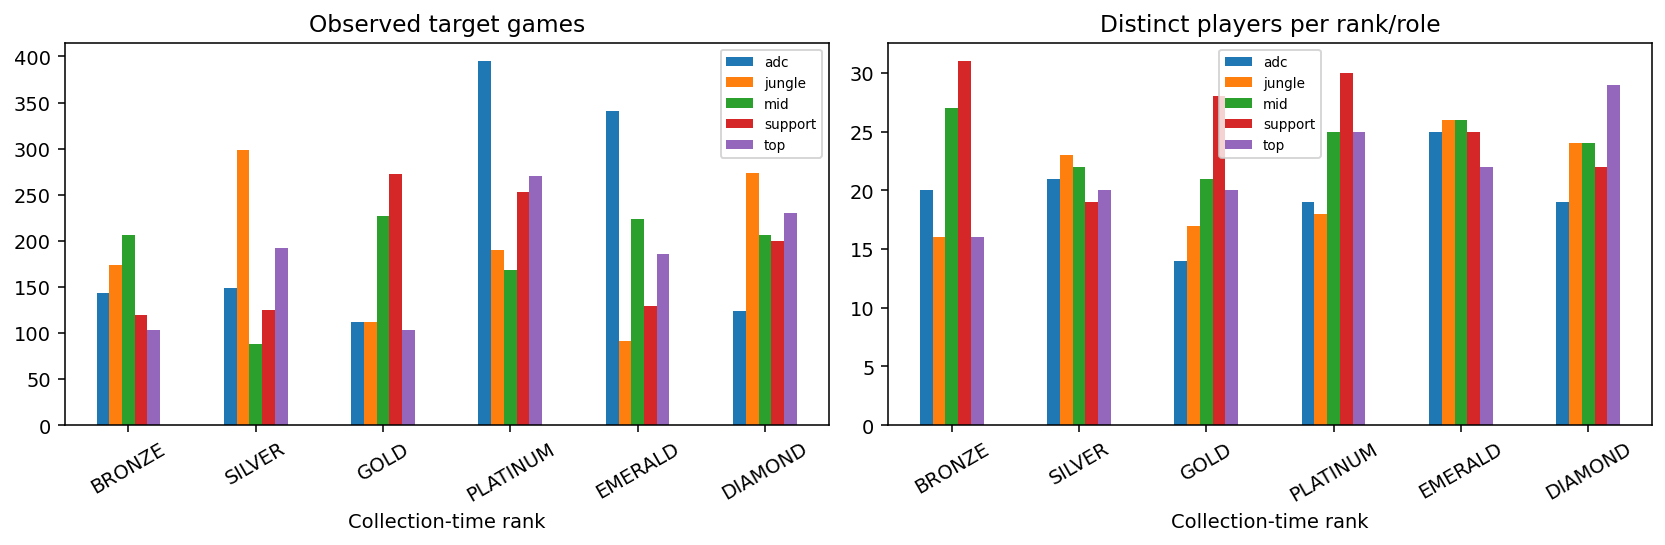

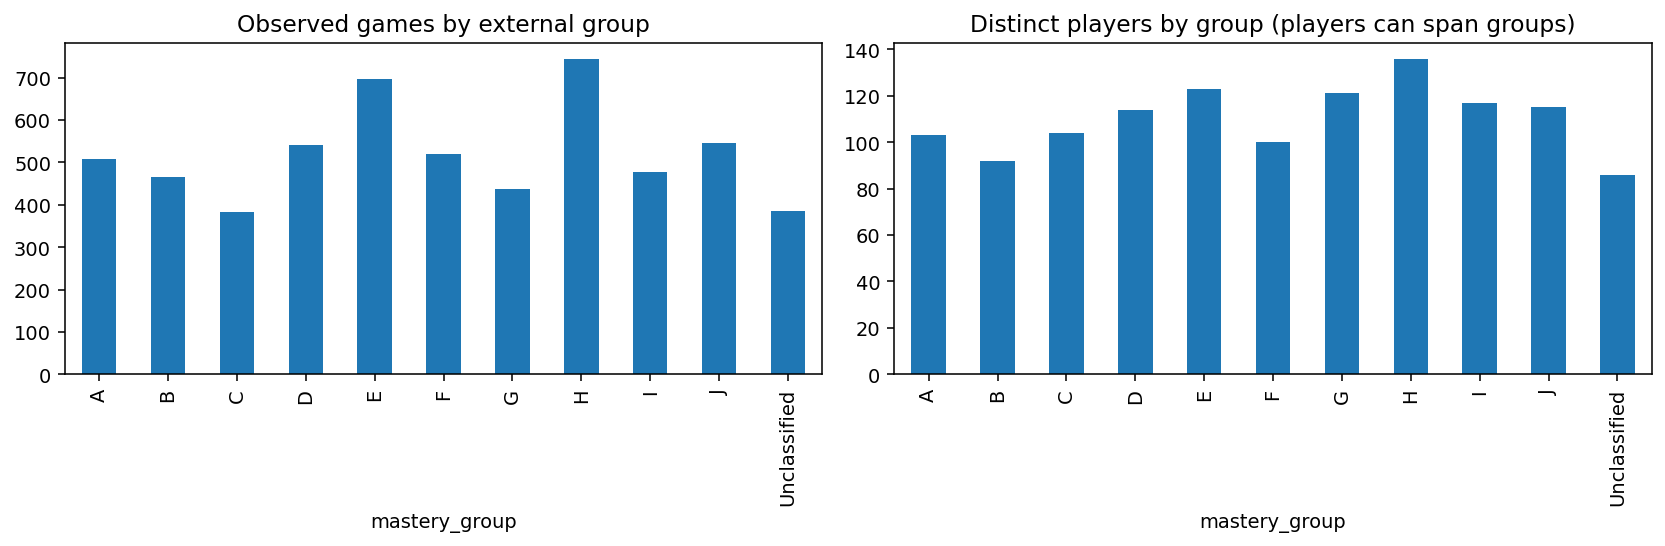

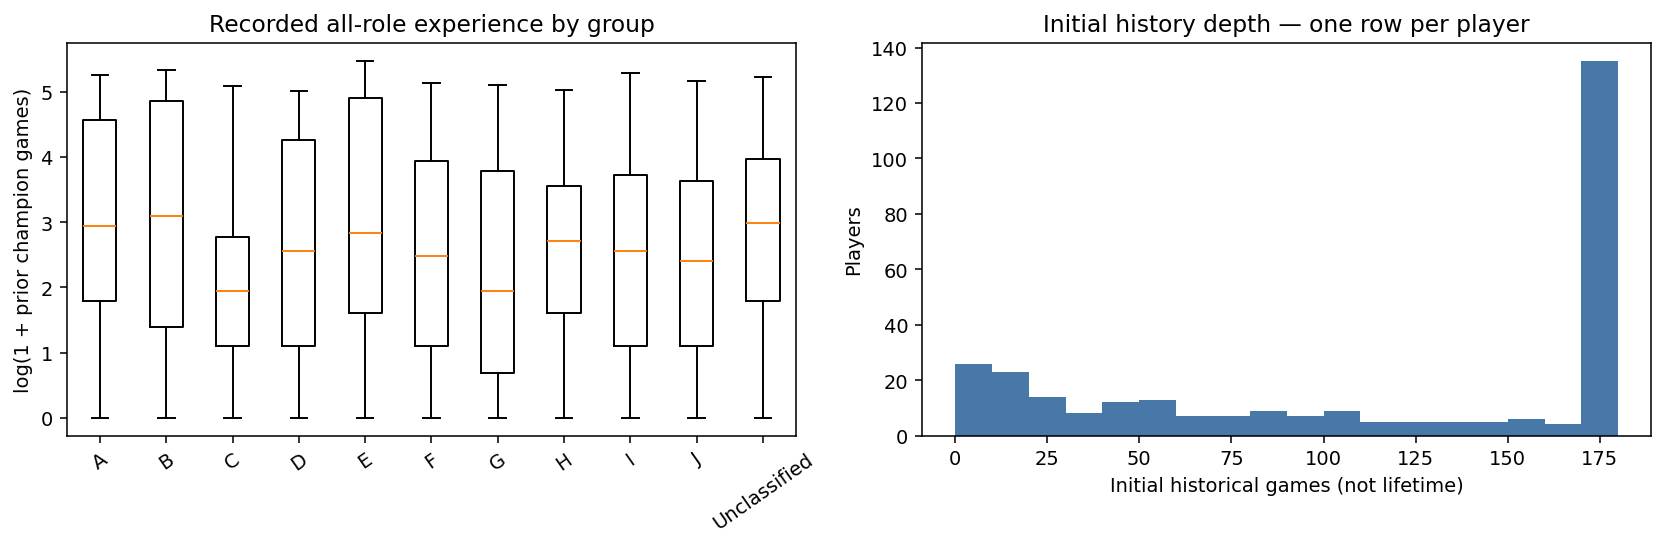

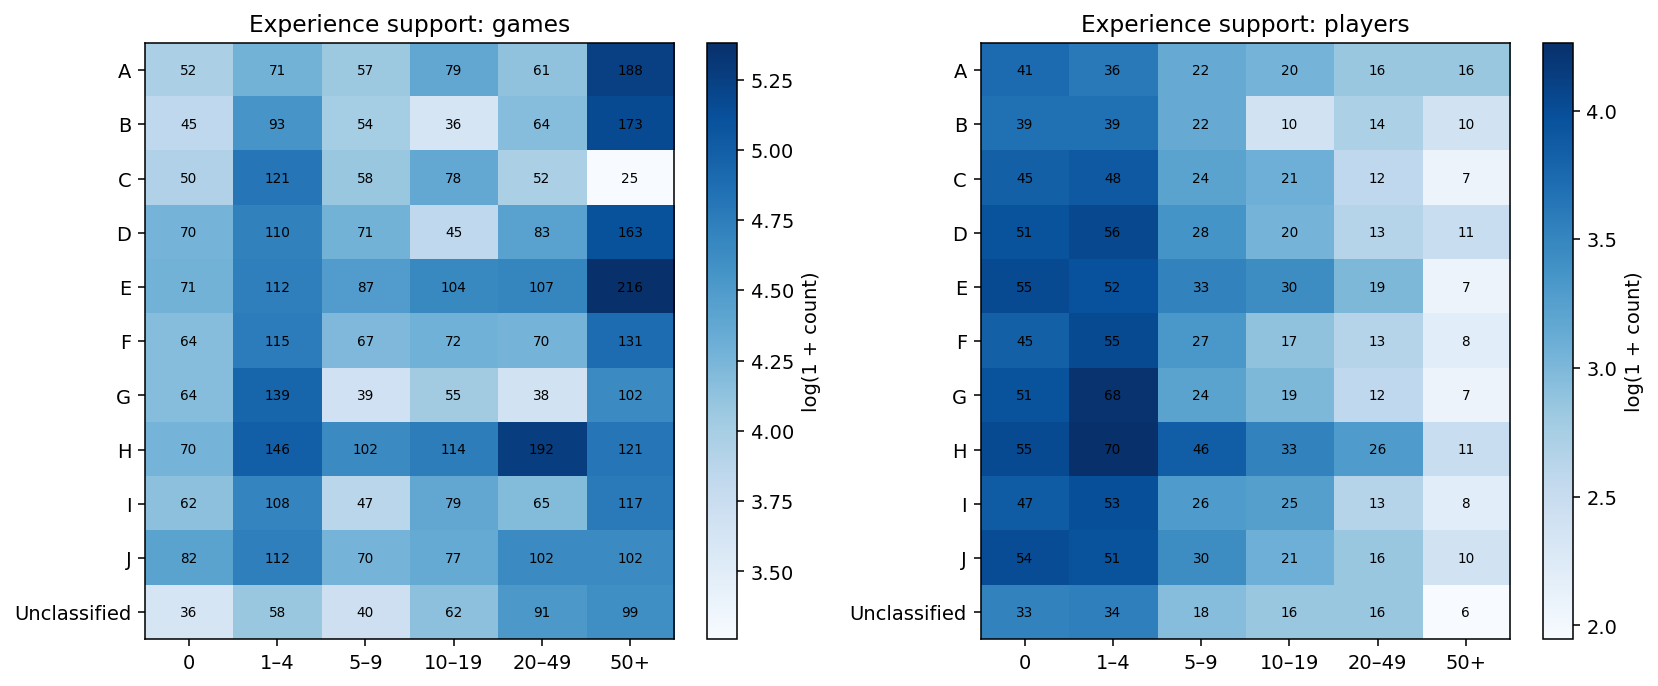

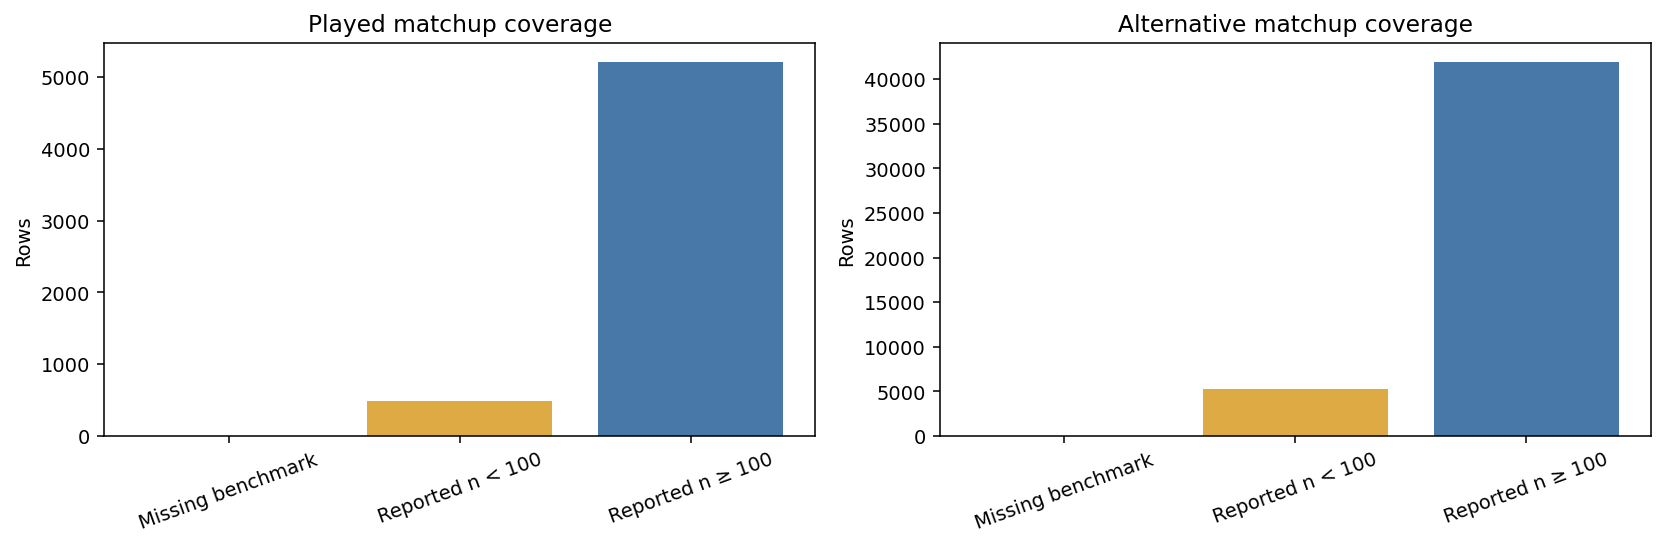

In [6]:
OUTPUT_PATH = modeling.prepare_outputs(
    PROJECT_ROOT, bundle, groups, study_rows, study_metadata, prepared, tables, CONFIG)
print('Analysis version:', OUTPUT_PATH.relative_to(PROJECT_ROOT))
print('Prepared data, source/grouping metadata, coverage tables, split assignments and figures saved.')
for name in ('rank_role_support','group_support','experience_and_history','experience_bin_support','matchup_coverage'):
    display(Image(filename=str(OUTPUT_PATH / 'figures' / (name + '.png'))))

## 6a. Five presentation figures — training player-games only

Run this section on its own; it reads the existing verified preparation and does not run collection, preparation exports, or model fitting. `RUN_MODELING` stays `False`. Only observed played rows in the saved **training** partition are loaded; alternative picks and final-test outcomes are not used.

Figures 1–4 compare actual win rate with the mean raw **LoLalytics Global, exact tier, patch 16.19** probability on exactly the same matched rows. Undefined usage ratios are excluded only from Figure 1; no additional history threshold is imposed. Empty categories have no estimated rate. Counts under categories are matched player-games and distinct players.

Wilson intervals assume independent games; repeated games from the same players may make them too narrow. Comparisons are descriptive, not causal or formal tests against the benchmark.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from statsmodels.stats.proportion import proportion_confint

assert globals().get('RUN_MODELING', False) is False, 'Keep RUN_MODELING=False.'
start = Path.cwd().resolve()
eda_root = next((p for p in [start, *start.parents, start / 'riot-game-prediction']
    if (p / 'hlr_model/broad_rank_modeling.ipynb').is_file()), None)
if eda_root is None:
    raise FileNotFoundError('Open from the repository root, hlr_model/, or its workspace.')
EDA_ANALYSIS = eda_root / 'hlr_model/data/analyses/broad_rank_mastery_v1/20261027T202619959682Z_2cff4897'
eda_file = EDA_ANALYSIS / 'prepared_played.parquet'
eda_manifest = json.loads((EDA_ANALYSIS / 'preparation_manifest.json').read_text())
assert hashlib.sha256(eda_file.read_bytes()).hexdigest() == eda_manifest['output_sha256']['prepared_played.parquet']
eda_columns = ['puuid', 'match_id', 'target_row_id', 'split', 'row_kind', 'win',
    'prior_champion_games', 'prior_total_games', 'prior_champion_usage_share',
    'n_recorded', 'model_rank', 'mastery_group', 'champion_id',
    'prior_main_champion_id', 'is_main_champion', 'benchmark_valid_rate',
    'benchmark_raw_matchup_winrate_probability']
eda_train = pd.read_parquet(eda_file, columns=eda_columns, filters=[('split', '==', 'train')])
assert eda_train.split.eq('train').all() and eda_train.row_kind.eq('played').all()
assert eda_train.win.isin([0, 1]).all() and not eda_train.duplicated(['puuid', 'match_id']).any()
assert eda_train.target_row_id.is_unique
n, total = eda_train.prior_champion_games, eda_train.prior_total_games
assert n.ge(0).all() and n.le(total).all() and n.mod(1).eq(0).all() and total.mod(1).eq(0).all()
assert eda_train.n_recorded.eq(n).all()
eda_train['usage_share'] = n / total.where(total.gt(0))
assert eda_train.loc[total.eq(0), 'prior_champion_usage_share'].isna().all()
assert np.allclose(eda_train.loc[total.gt(0), 'usage_share'],
                   eda_train.loc[total.gt(0), 'prior_champion_usage_share'])
raw = eda_train.benchmark_raw_matchup_winrate_probability
assert raw.loc[eda_train.benchmark_valid_rate & raw.notna()].between(0, 1).all()
eda_matched = eda_train.loc[eda_train.benchmark_valid_rate & raw.notna()].copy()
eda_matched['matchup_probability'] = eda_matched.benchmark_raw_matchup_winrate_probability
USAGE_LABELS = ['0–20%', '>20–40%', '>40–60%', '>60–80%', '>80–100%']
EXPERIENCE_LABELS = ['0', '1–4', '5–9', '10–19', '20–49', '50+']
RANK_LABELS = ['BRONZE', 'SILVER', 'GOLD', 'PLATINUM', 'EMERALD', 'DIAMOND']
GROUP_LABELS = list('ABCDEFGHIJ') + ['Unclassified']
eda_matched['usage_bin'] = pd.cut(eda_matched.usage_share, [0, .2, .4, .6, .8, 1],
    labels=USAGE_LABELS, right=True, include_lowest=True)
eda_matched['experience_bin'] = pd.cut(eda_matched.prior_champion_games,
    [-.5, .5, 4.5, 9.5, 19.5, 49.5, np.inf], labels=EXPERIENCE_LABELS)

# Small shared summaries/plotting functions, used only by the five inline figures.
def eda_rates(frame, category, levels):
    result = frame.groupby(category, observed=True).agg(
        wins=('win', 'sum'), games=('win', 'size'), players=('puuid', 'nunique'),
        baseline=('matchup_probability', 'mean')).reindex(levels)
    result[['wins', 'games', 'players']] = result[['wins', 'games', 'players']].fillna(0).astype(int)
    result['observed_wr'] = result.wins / result.games.where(result.games.gt(0))
    result['ci_low'] = np.nan
    result['ci_high'] = np.nan
    present = result.games.gt(0)
    low, high = proportion_confint(result.loc[present, 'wins'].to_numpy(),
        result.loc[present, 'games'].to_numpy(), alpha=.05, method='wilson')
    result.loc[present, 'ci_low'] = low
    result.loc[present, 'ci_high'] = high
    assert result.loc[~present, ['observed_wr', 'baseline', 'ci_low', 'ci_high']].isna().all().all()
    return result

def eda_rate_plot(summary, title, xlabel, *, separate_unclassified=False, show_ci=True):
    x = np.arange(len(summary), dtype=float)
    if separate_unclassified:
        x[-1] += .8
    fig, ax = plt.subplots(figsize=(14.5 if separate_unclassified else 13, 7))
    fig.suptitle(title + '\nTraining player-games', fontsize=18, fontweight='bold', y=.98)
    if show_ci:
        errors = np.vstack([summary.observed_wr - summary.ci_low,
                            summary.ci_high - summary.observed_wr])
        ax.errorbar(x - .035, summary.observed_wr, yerr=np.maximum(errors, 0),
            fmt='o' if separate_unclassified else 'o-', color='#2563A6',
            linewidth=1.7, capsize=4, markersize=6, label='Observed WR (95% Wilson CI)')
    else:
        ax.plot(x - .035, summary.observed_wr, marker='o',
            linestyle='none' if separate_unclassified else '-', color='#2563A6',
            linewidth=1.7, markersize=6, label='Observed WR')
    ax.plot(x + .035, summary.baseline, marker='D',
        linestyle='none' if separate_unclassified else '--', color='#D18128',
        linewidth=1.7, markersize=5, label='Mean matchup baseline')
    if separate_unclassified:
        ax.axvline((x[-2] + x[-1]) / 2, color='#D7DCE3', linewidth=1)
    labels = [str(label).title() if str(label) in RANK_LABELS else str(label) for label in summary.index]
    ax.set_xticks(x, [f'{label}\n{row.games:,} games\n{row.players} players'
        for label, row in zip(labels, summary.itertuples())])
    ax.tick_params(labelsize=11)
    ax.set(xlabel=xlabel, ylabel='Win rate', facecolor='white')
    ax.xaxis.label.set_size(13)
    ax.yaxis.label.set_size(13)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y', color='#E4E8EE', linewidth=.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, 1.16), ncol=2,
              frameon=False, fontsize=12)
    fig.text(.5, .025, 'Baseline: LoLalytics Global, exact tier, patch 16.19. '
             'Both rates use the same matched rows.', ha='center', fontsize=10, color='#4B5563')
    fig.subplots_adjust(left=.08, right=.96, top=.77, bottom=.26)
    return fig, ax

print('Verified preparation:', EDA_ANALYSIS.name)
print(f'Training: {len(eda_train):,} played games / {eda_train.puuid.nunique()} players; '
      f'matched benchmarks: {len(eda_matched):,}; missing benchmarks: {len(eda_train)-len(eda_matched)}.')
print(f'Undefined usage shares: {eda_train.usage_share.isna().sum()}; no additional history cutoff.')


Verified preparation: 20261027T202619959682Z_2cff4897
Training: 3,908 played games / 265 players; matched benchmarks: 3,907; missing benchmarks: 1.
Undefined usage shares: 5; no additional history cutoff.


### 1. OTP rate versus win rate

“OTP rate” here means the **pregame usage share of the champion actually played**, our continuous specialization measure. It is not the player's most-played-champion share. Bins are `[0,.2]`, `(.2,.4]`, `(.4,.6]`, `(.6,.8]`, `(.8,1]`, with no gaps or overlaps. Undefined ratios are excluded; very short histories can still look highly specialized.


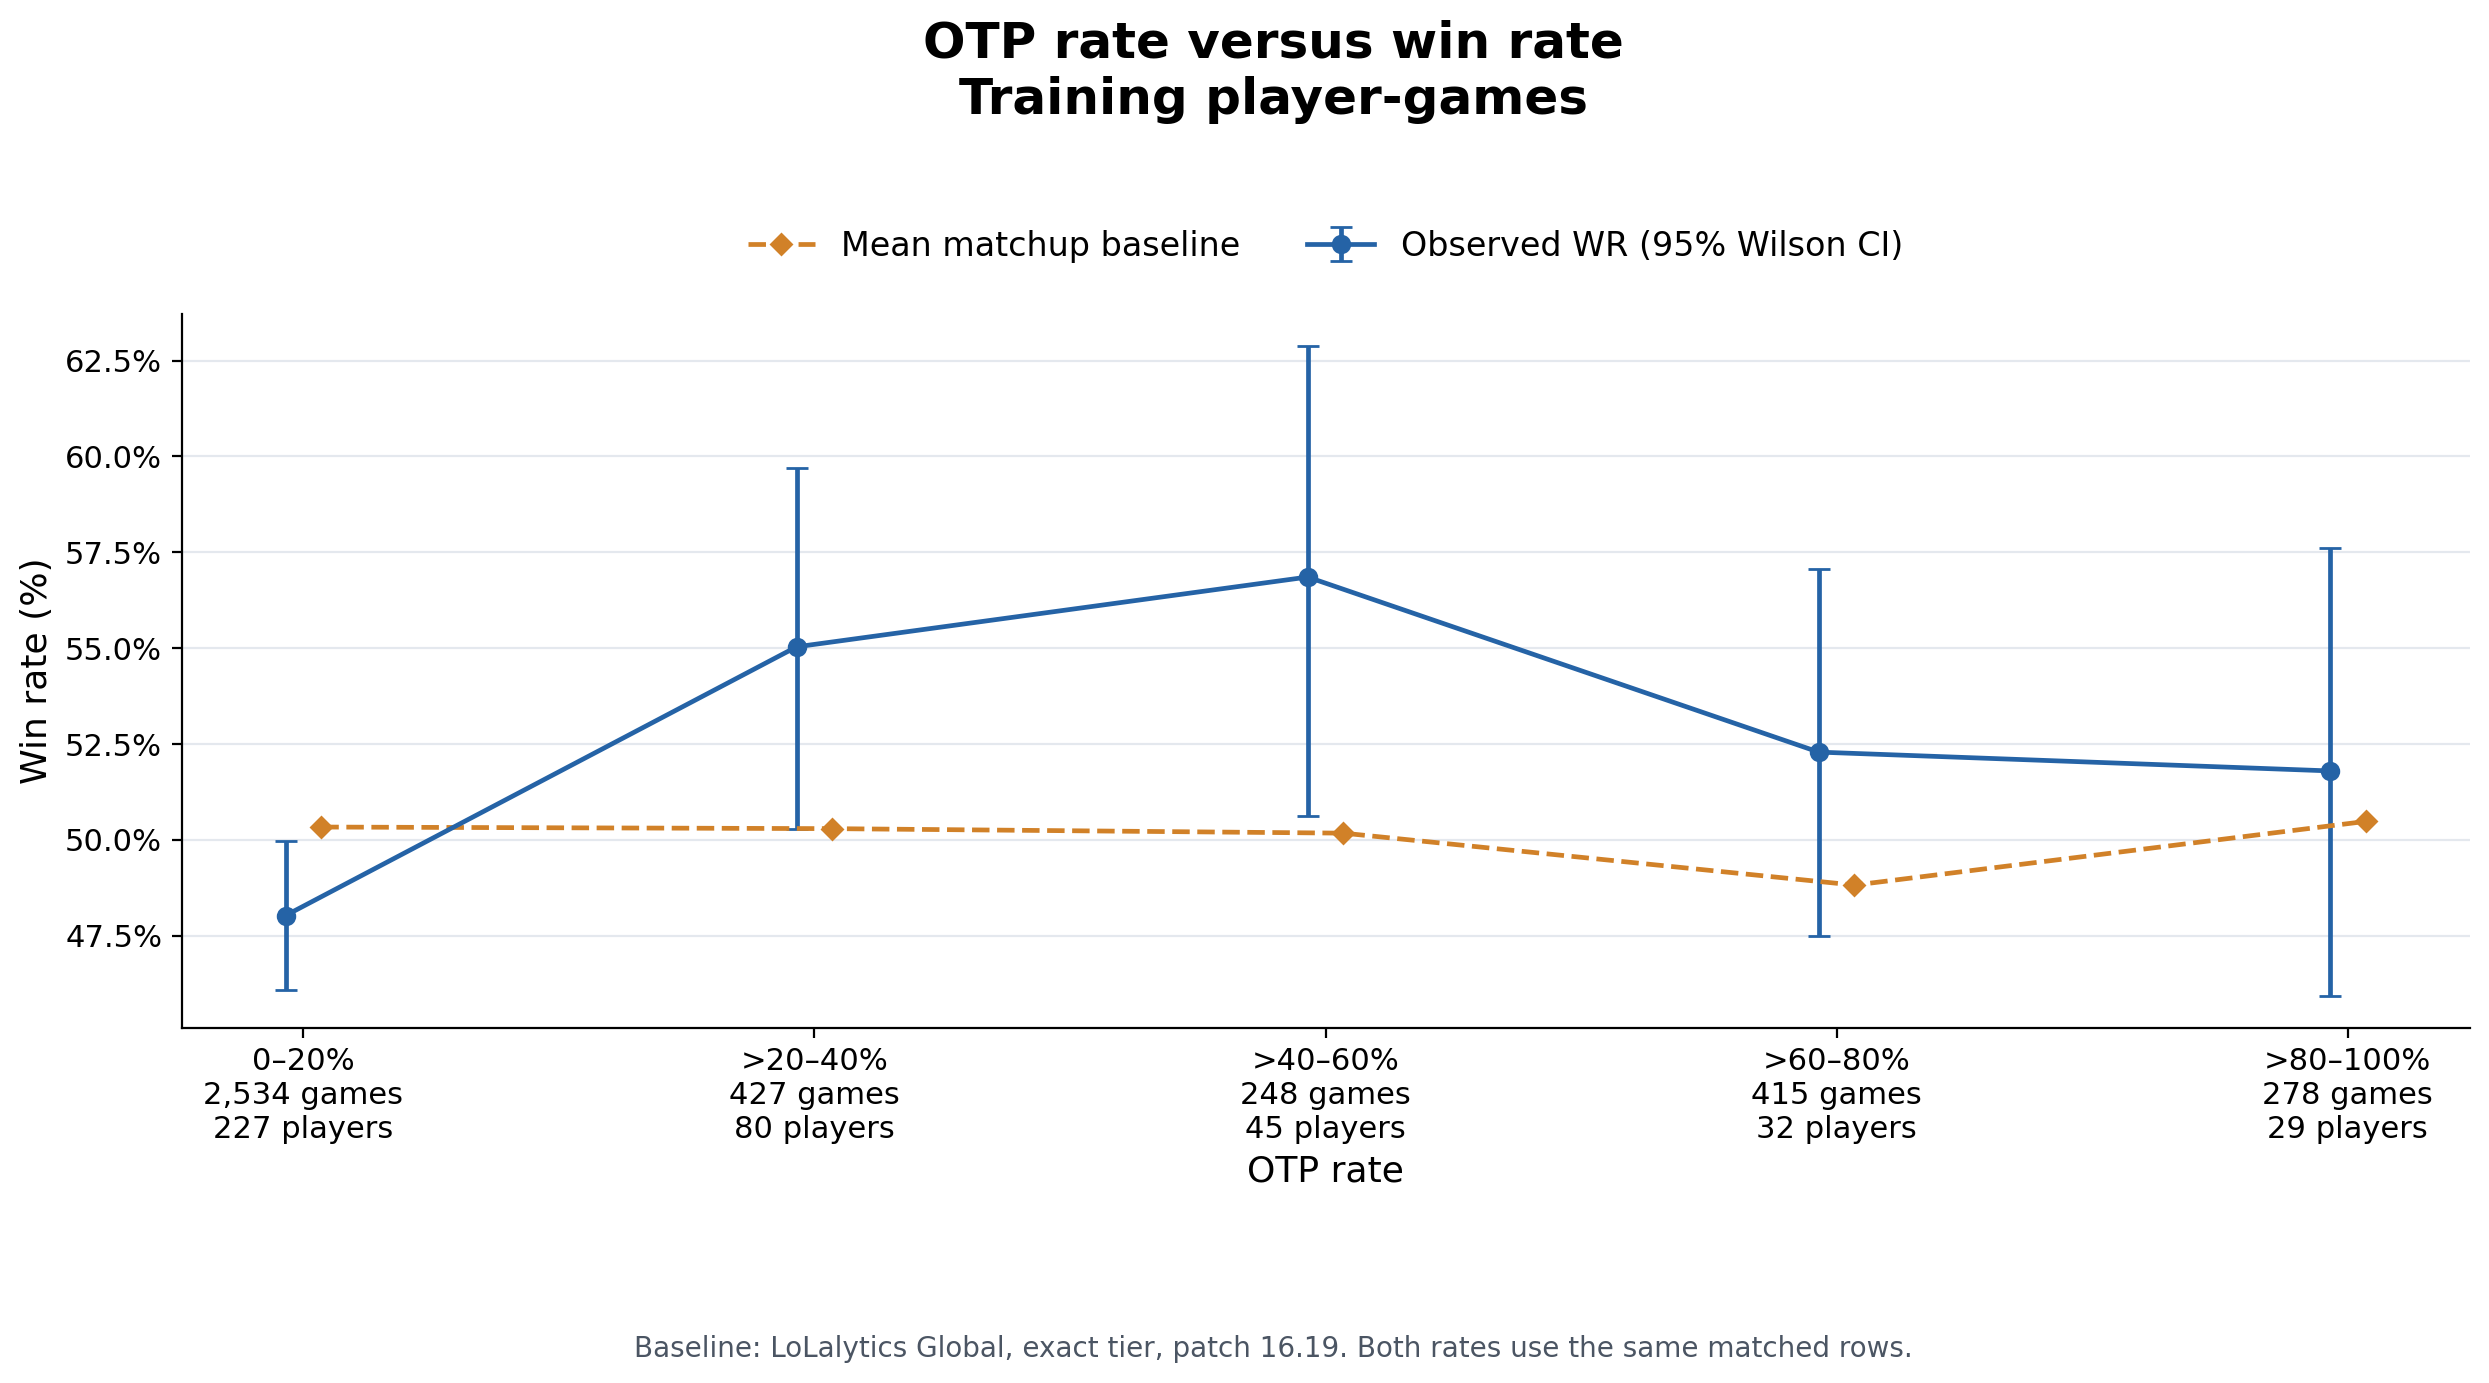

In [2]:
eda_usage = eda_rates(eda_matched.loc[eda_matched.usage_share.notna()], 'usage_bin', USAGE_LABELS)
eda_usage_ci_fig, eda_usage_ci_ax = eda_rate_plot(eda_usage, 'OTP rate versus win rate', 'OTP rate')
eda_usage_ci_ax.set_ylabel('Win rate (%)')
eda_usage_ci_limits = (eda_usage_ci_ax.get_xlim(), eda_usage_ci_ax.get_ylim())
plt.show()


### 2. Champion experience versus win rate

Experience means recorded prior **all-role** champion games from the existing expanding history. It is not lifetime play or Riot mastery points; zero does not establish first-ever play.


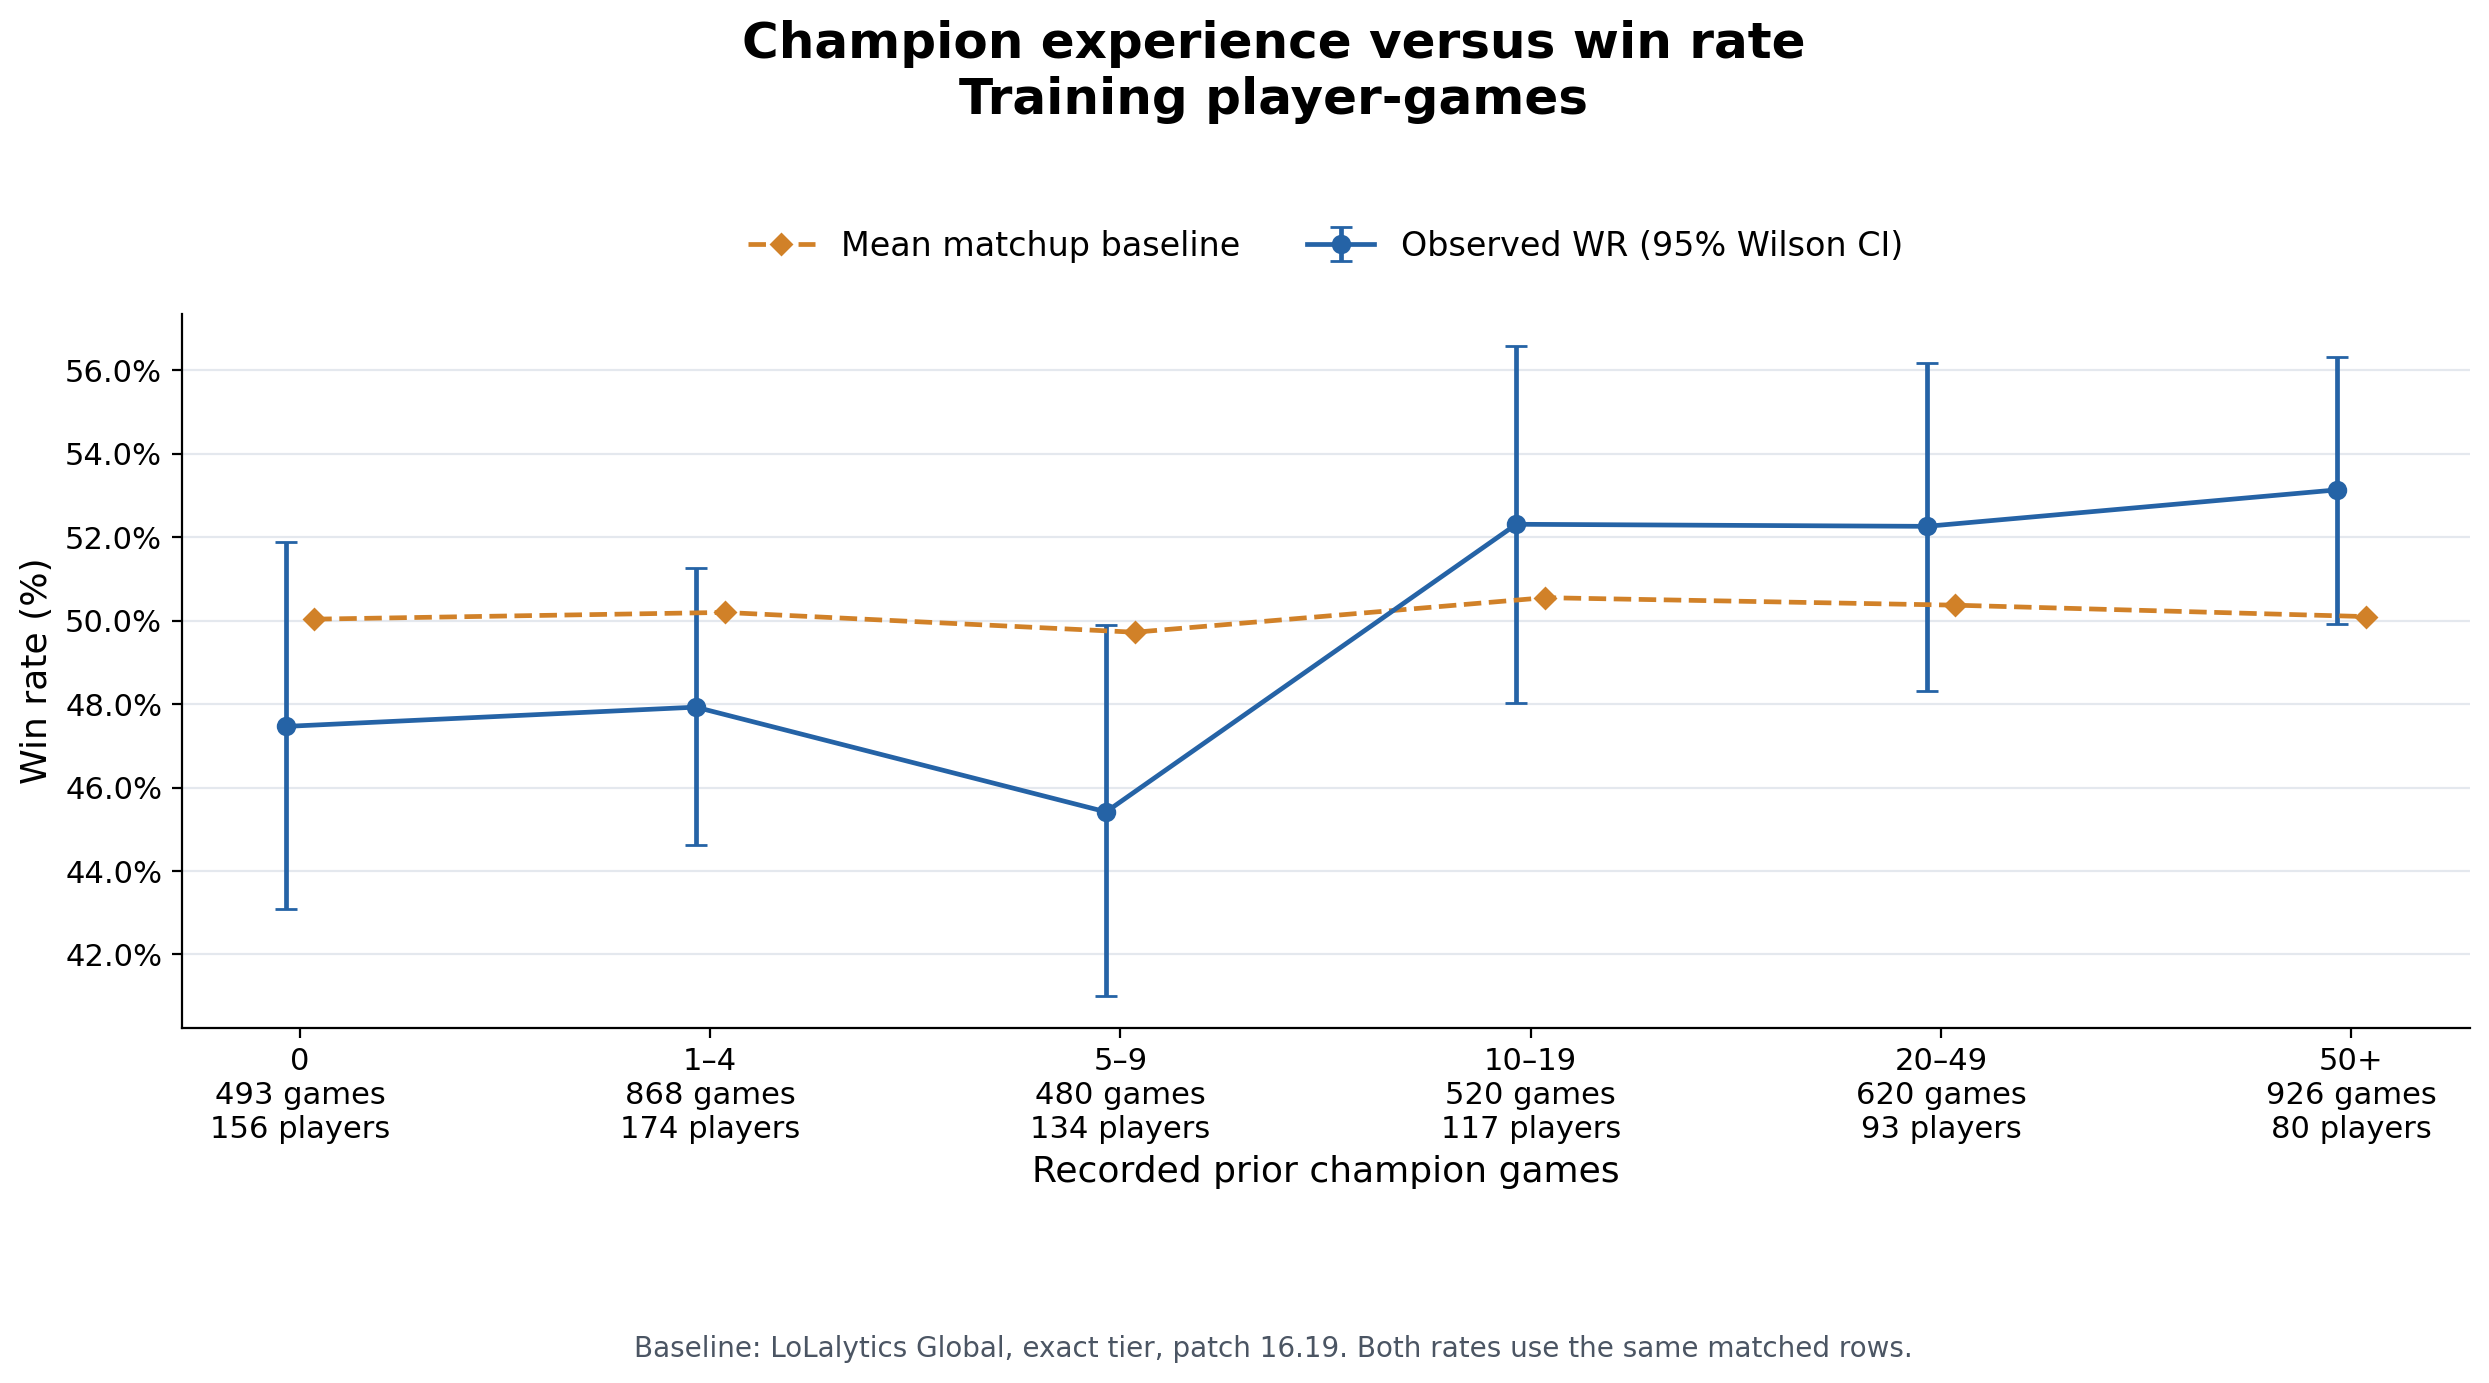

In [3]:
eda_experience = eda_rates(eda_matched, 'experience_bin', EXPERIENCE_LABELS)
eda_experience_ci_fig, eda_experience_ci_ax = eda_rate_plot(
    eda_experience, 'Champion experience versus win rate', 'Recorded prior champion games')
eda_experience_ci_ax.set_ylabel('Win rate (%)')
eda_experience_ci_limits = (eda_experience_ci_ax.get_xlim(), eda_experience_ci_ax.get_ylim())
plt.show()


### 3. Observed versus baseline win rate by rank

Within each collection-time rank, the observed rate and mean benchmark use exactly the same training player-games. Raw bracket benchmarks are not assumed to equal 50%.


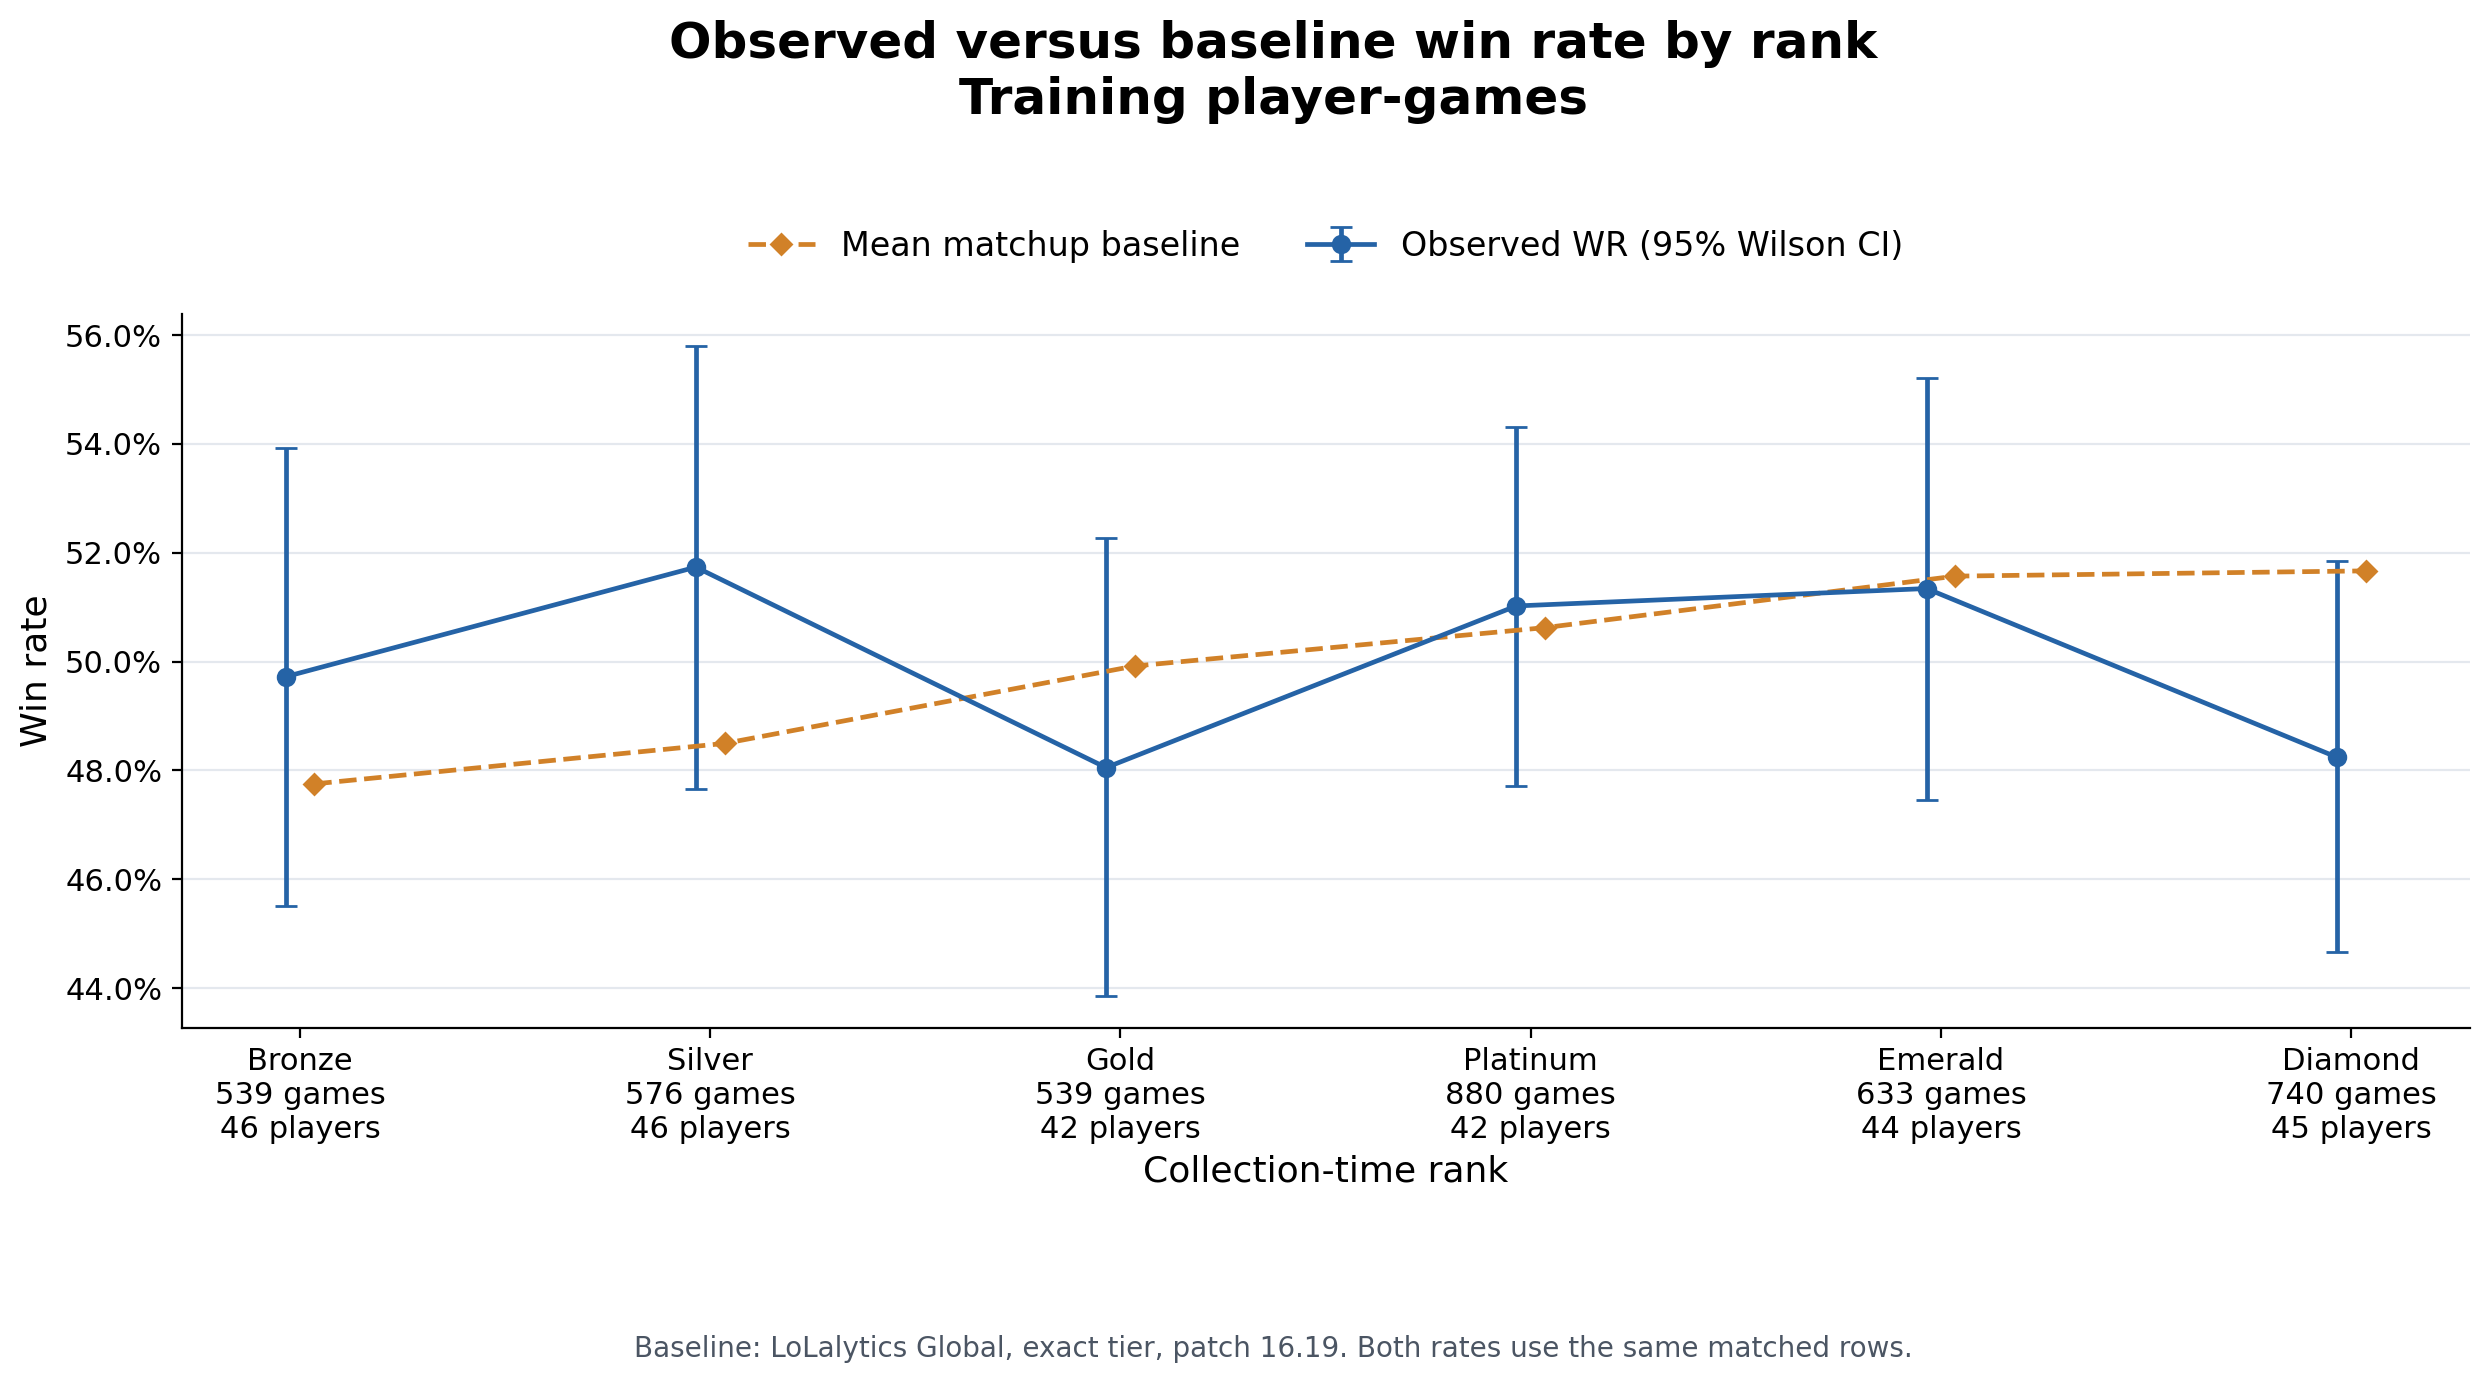

In [4]:
eda_rank = eda_rates(eda_matched, 'model_rank', RANK_LABELS)
eda_rate_plot(eda_rank, 'Observed versus baseline win rate by rank', 'Collection-time rank')
plt.show()


### 4. Observed versus baseline win rate by mastery-payoff group

A–J are external champion classifications based on high-minus-medium mastery results; the plotted outcomes come from **our own training player-games**. Unclassified is displayed separately. This is an overall descriptive comparison, not an estimated learning curve or proof that group A benefits more from practice.


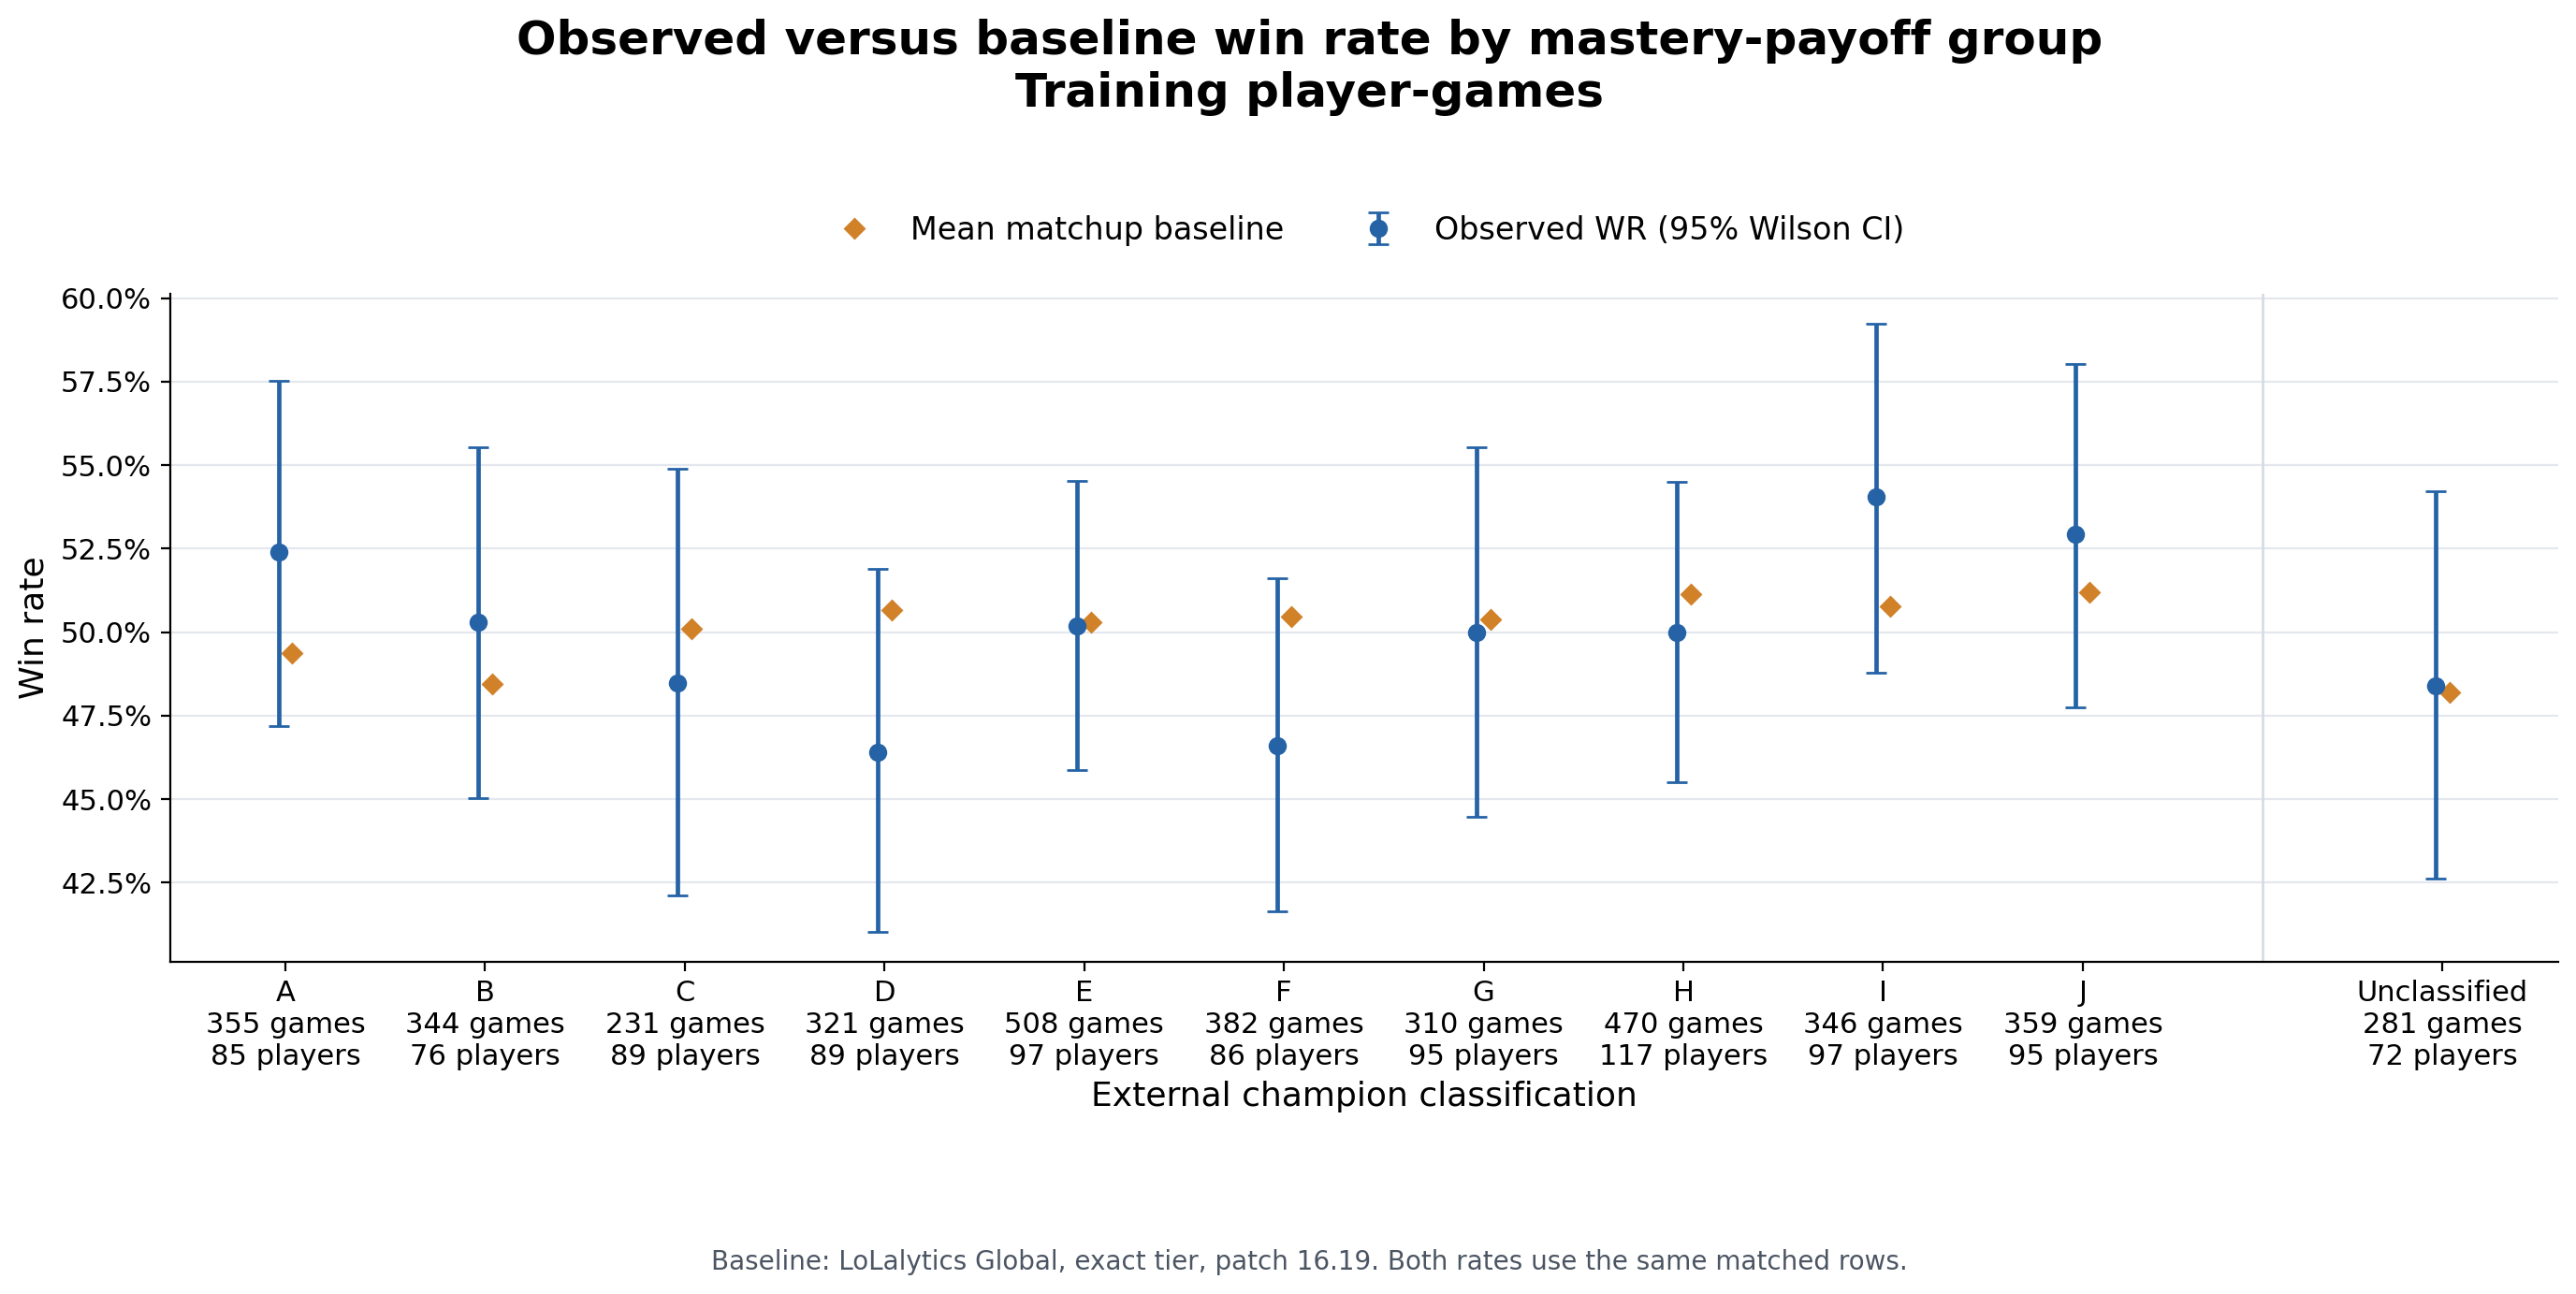

In [5]:
eda_groups = eda_rates(eda_matched, 'mastery_group', GROUP_LABELS)
eda_rate_plot(eda_groups, 'Observed versus baseline win rate by mastery-payoff group',
              'External champion classification', separate_unclassified=True)
plt.show()


### 5. Experience coverage

Cells count distinct players in the matched training rows used for the experience comparisons. Players can appear in multiple cells. Read high-experience cells cautiously when only a few players contribute; a large game count is not the same as broad player support.


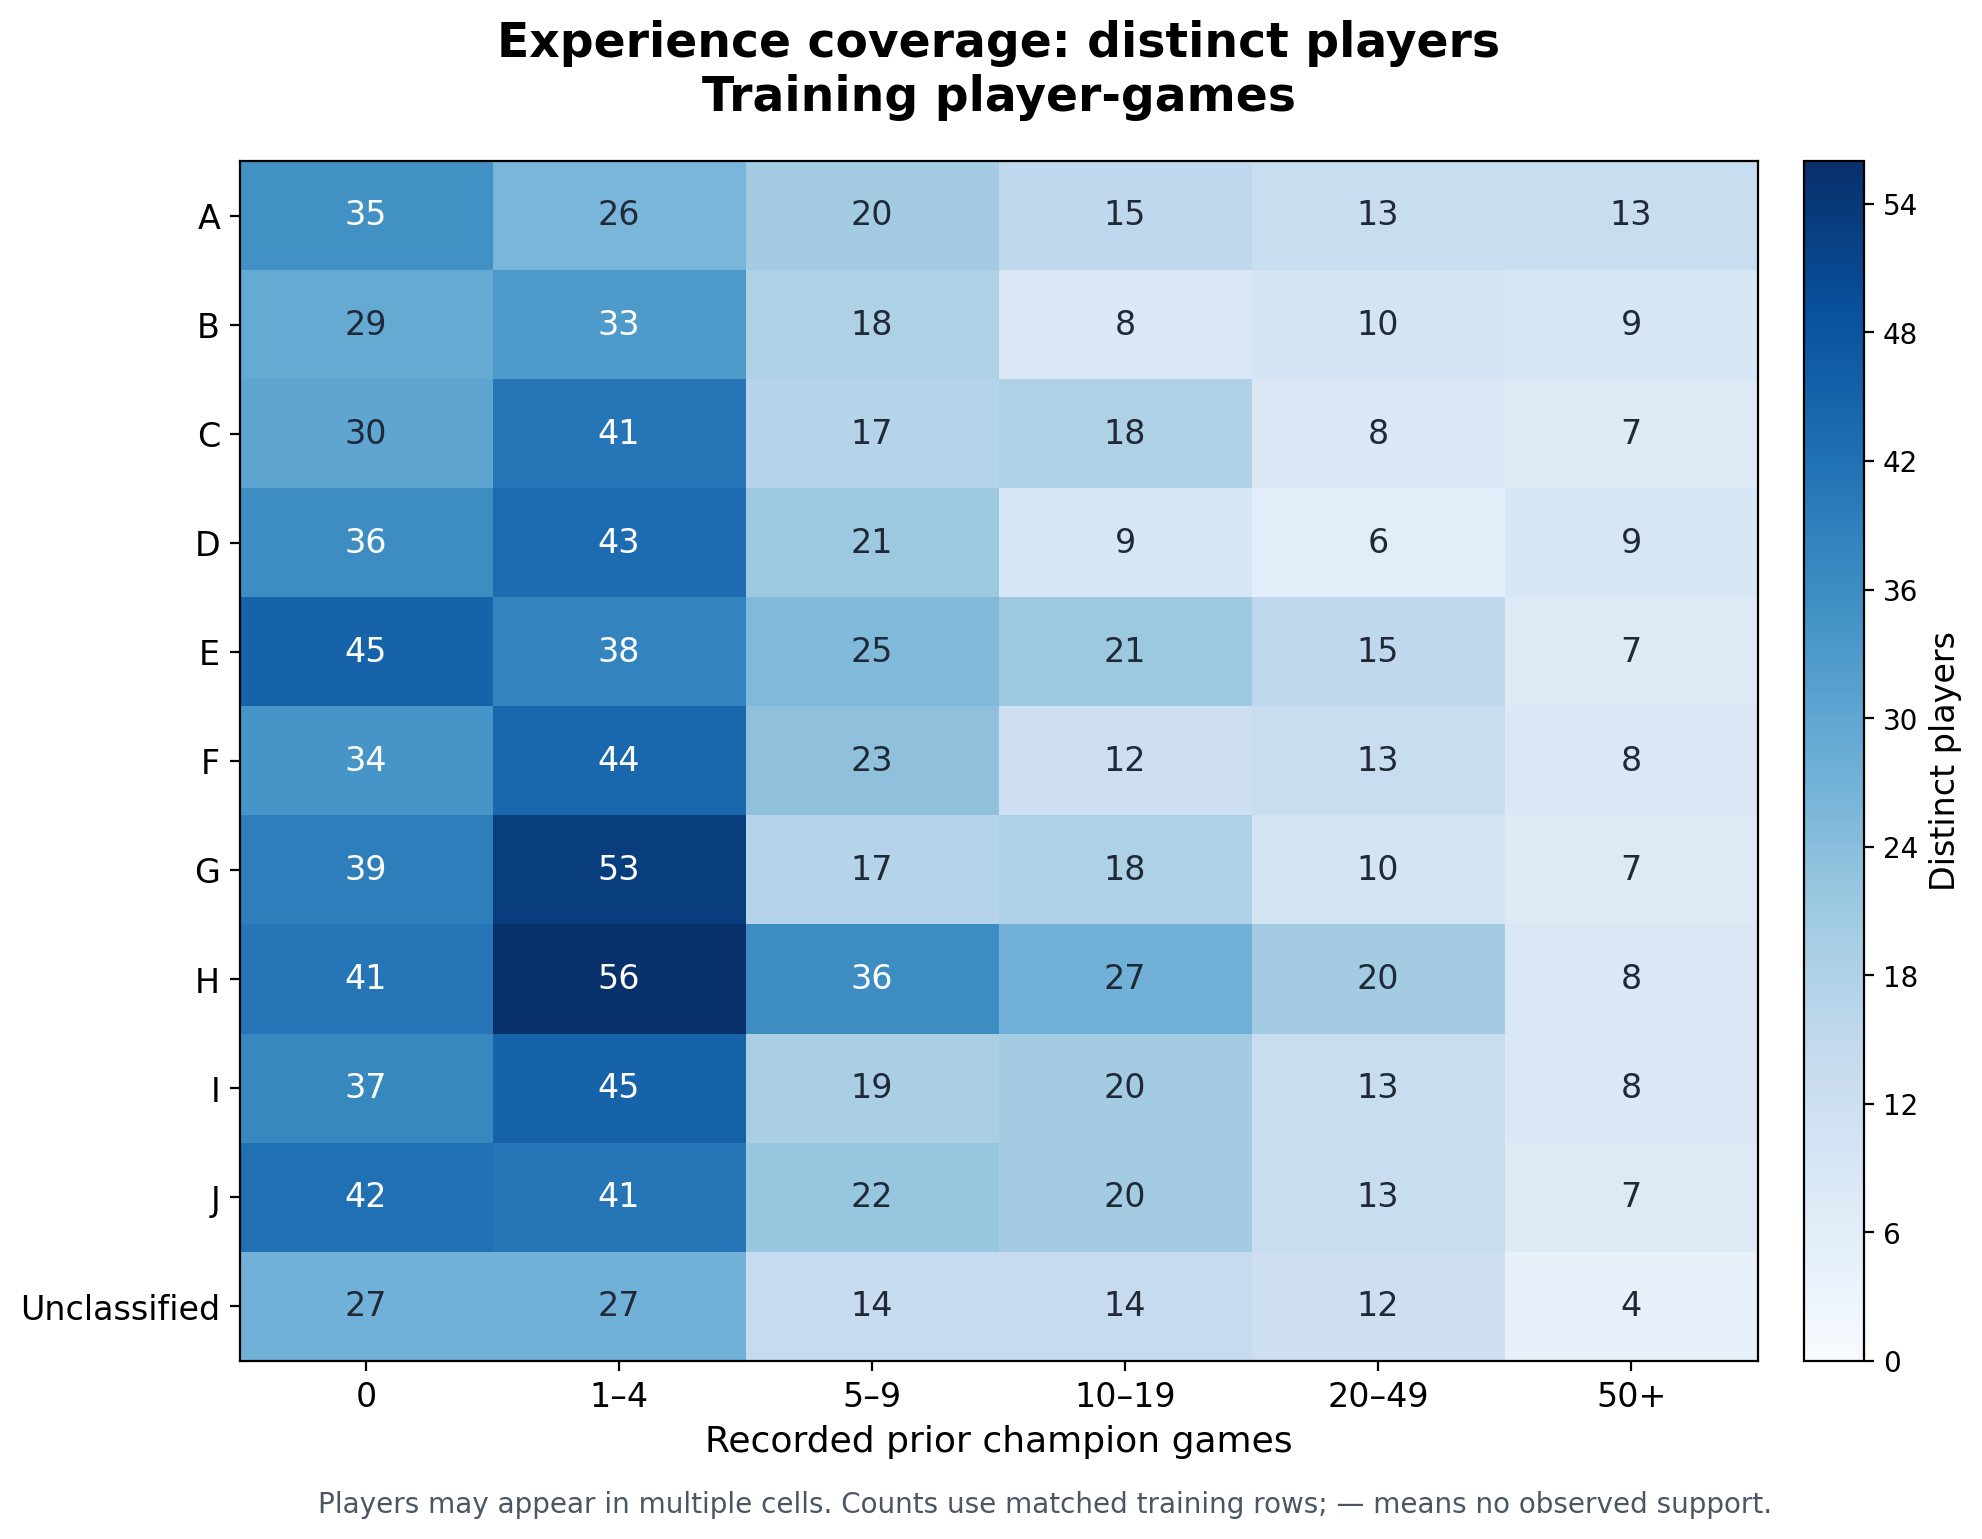

In [6]:
eda_player_coverage = (eda_matched.groupby(['mastery_group', 'experience_bin'], observed=True)
    .puuid.nunique().unstack('experience_bin').reindex(index=GROUP_LABELS, columns=EXPERIENCE_LABELS))
fig, ax = plt.subplots(figsize=(11.5, 8))
image = ax.imshow(np.ma.masked_invalid(eda_player_coverage.to_numpy(dtype=float)),
                  cmap='Blues', aspect='auto', vmin=0)
maximum = np.nanmax(eda_player_coverage.to_numpy(dtype=float))
for i in range(len(GROUP_LABELS)):
    for j in range(len(EXPERIENCE_LABELS)):
        value = eda_player_coverage.iloc[i, j]
        ax.text(j, i, '—' if pd.isna(value) else str(int(value)), ha='center', va='center',
                fontsize=12, color='white' if pd.notna(value) and value > .55 * maximum else '#1F2937')
ax.set_xticks(range(len(EXPERIENCE_LABELS)), EXPERIENCE_LABELS, fontsize=12)
ax.set_yticks(range(len(GROUP_LABELS)), GROUP_LABELS, fontsize=12)
ax.set_xlabel('Recorded prior champion games', fontsize=13)
ax.set_title('Experience coverage: distinct players\nTraining player-games', fontsize=17, fontweight='bold', pad=18)
colorbar = fig.colorbar(image, ax=ax, pad=.025)
colorbar.set_label('Distinct players', fontsize=12)
colorbar.locator = MaxNLocator(integer=True)
colorbar.update_ticks()
fig.text(.5, .025, 'Players may appear in multiple cells. Counts use matched training rows; '
         '— means no observed support.', ha='center', fontsize=10, color='#4B5563')
fig.subplots_adjust(left=.15, right=.95, top=.87, bottom=.12)
plt.show()


## 6b. Five additional plotting views — training data only

These reuse the same prepared observed games, matching rules, OTP bins, recorded experience, and colors above. No alternative picks supply outcomes. The first two additions omit confidence intervals and use exactly the corresponding original axis limits; the three further plots are descriptive views without additional CIs. Model fitting remains disabled.


### 6. OTP rate versus win rate — without confidence intervals

Same observations, benchmark means, bin counts and axis limits as Figure 1.


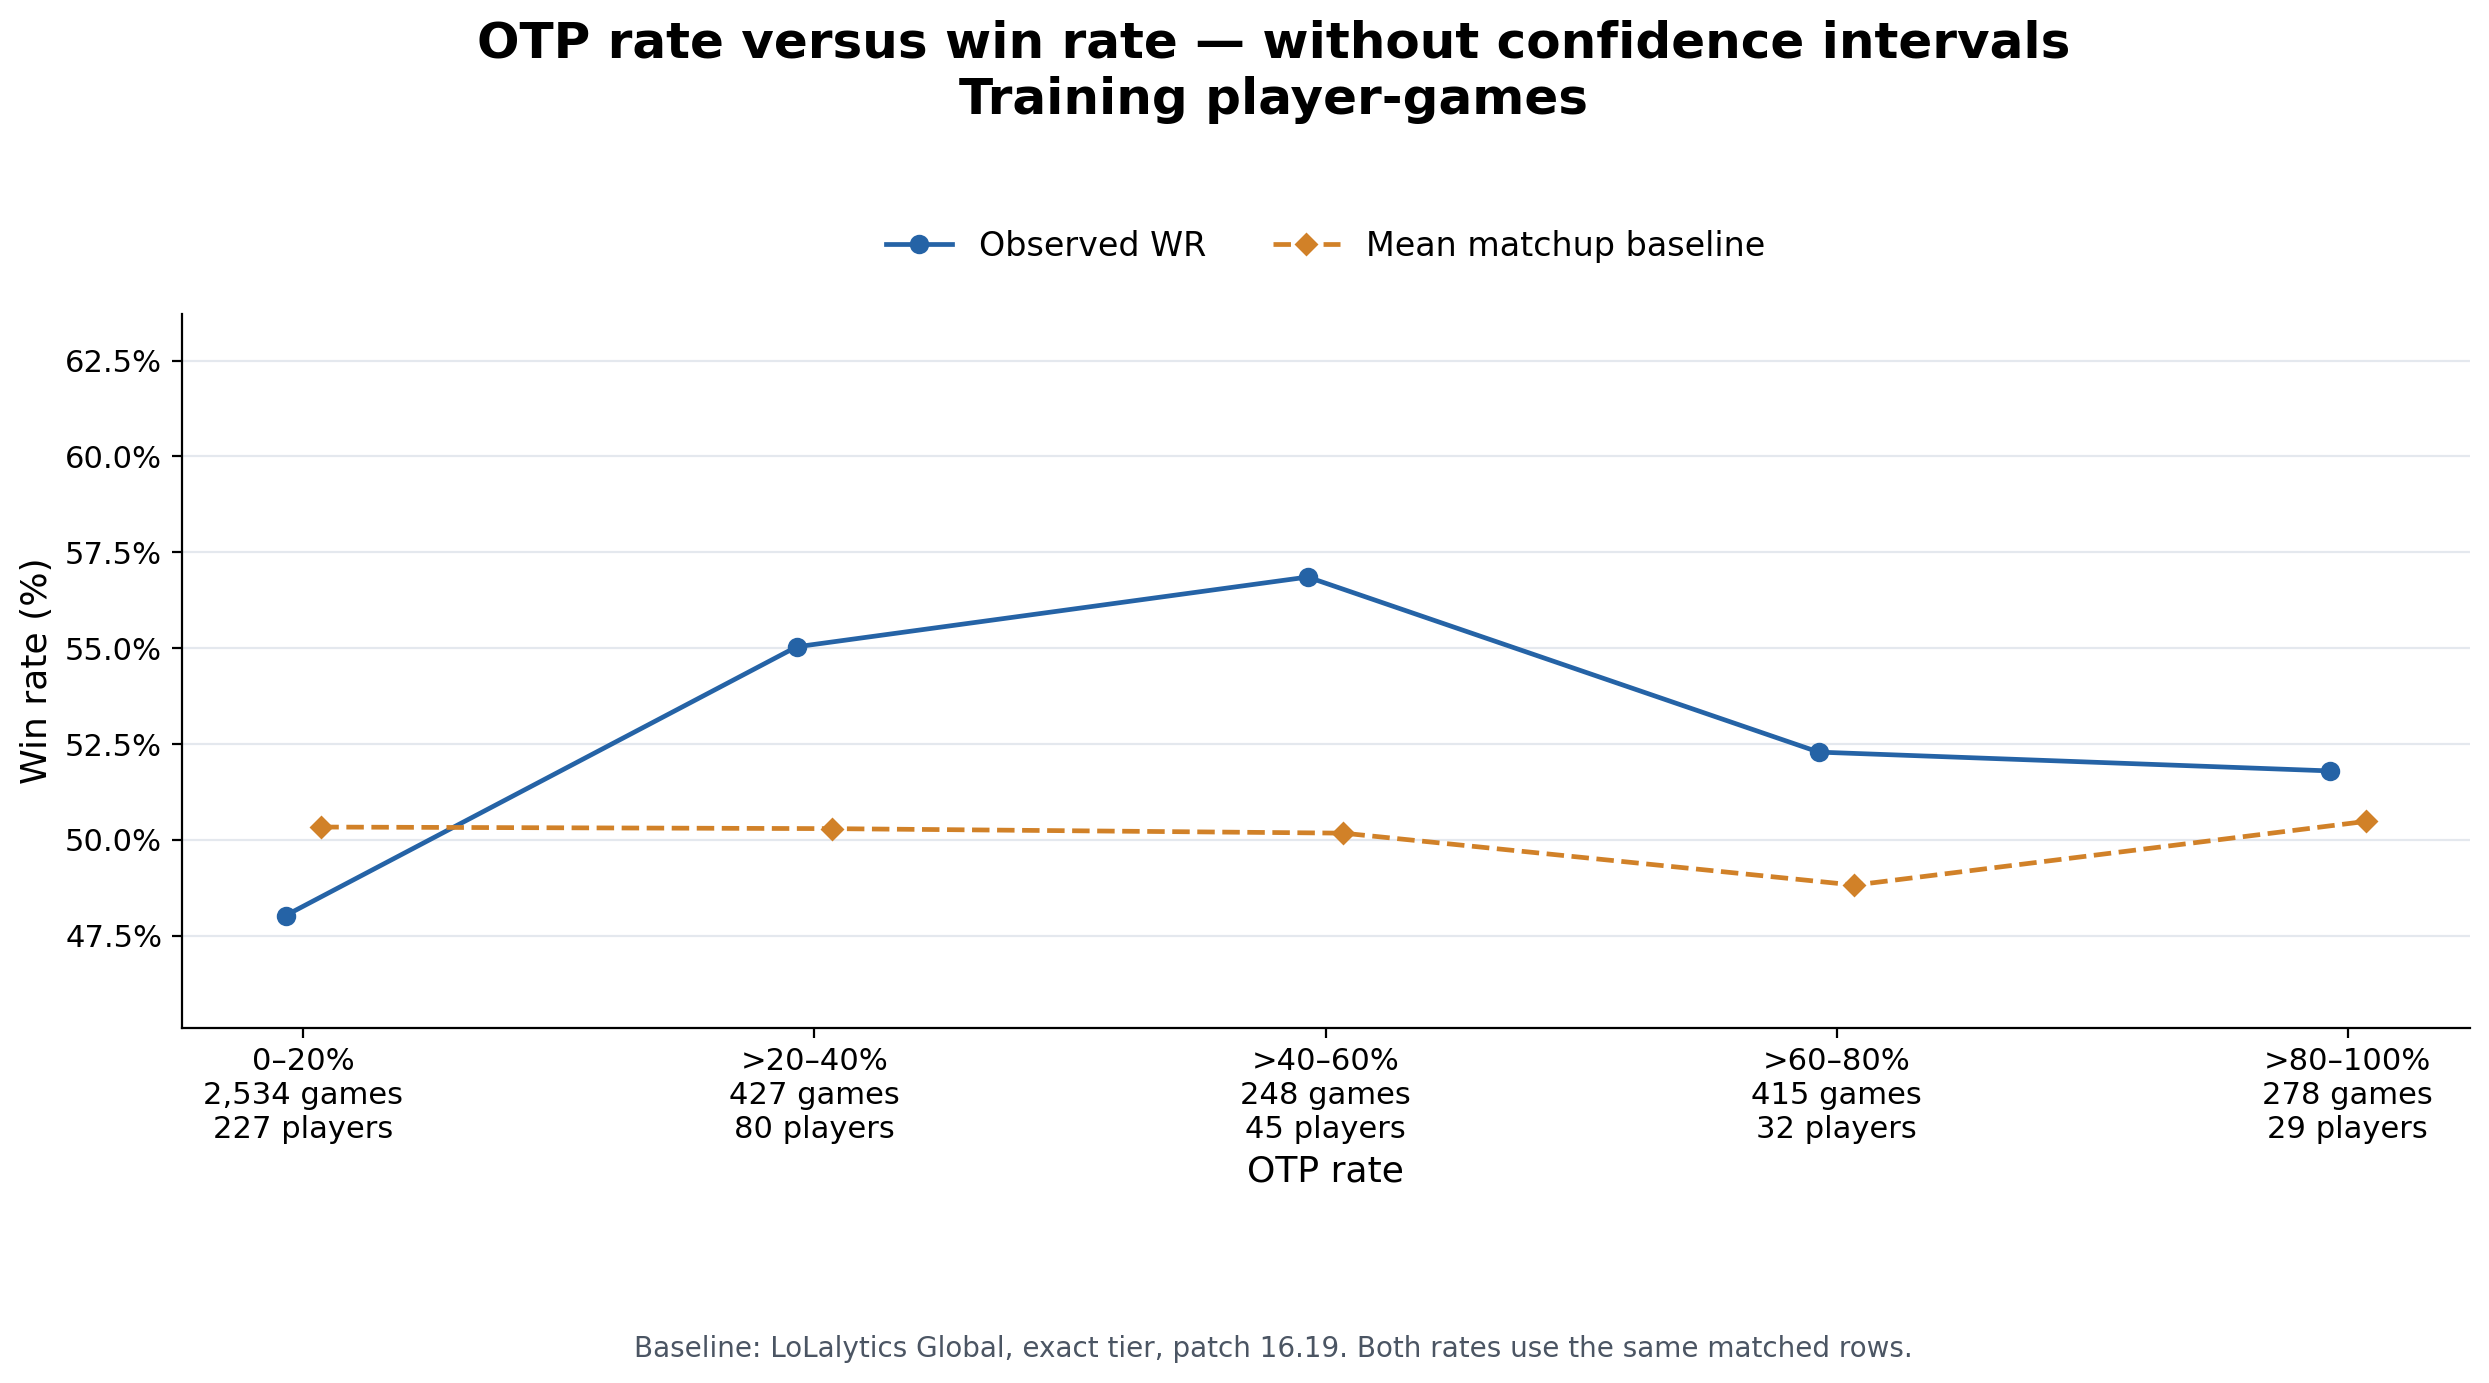

In [4]:
eda_usage_plain_fig, eda_usage_plain_ax = eda_rate_plot(
    eda_usage, 'OTP rate versus win rate — without confidence intervals', 'OTP rate', show_ci=False)
eda_usage_plain_ax.set_ylabel('Win rate (%)')
eda_usage_plain_ax.set_xlim(eda_usage_ci_limits[0])
eda_usage_plain_ax.set_ylim(eda_usage_ci_limits[1])
plt.show()


### 7. Champion experience versus win rate — without confidence intervals

Same observations, benchmark means, bin counts and axis limits as Figure 2.


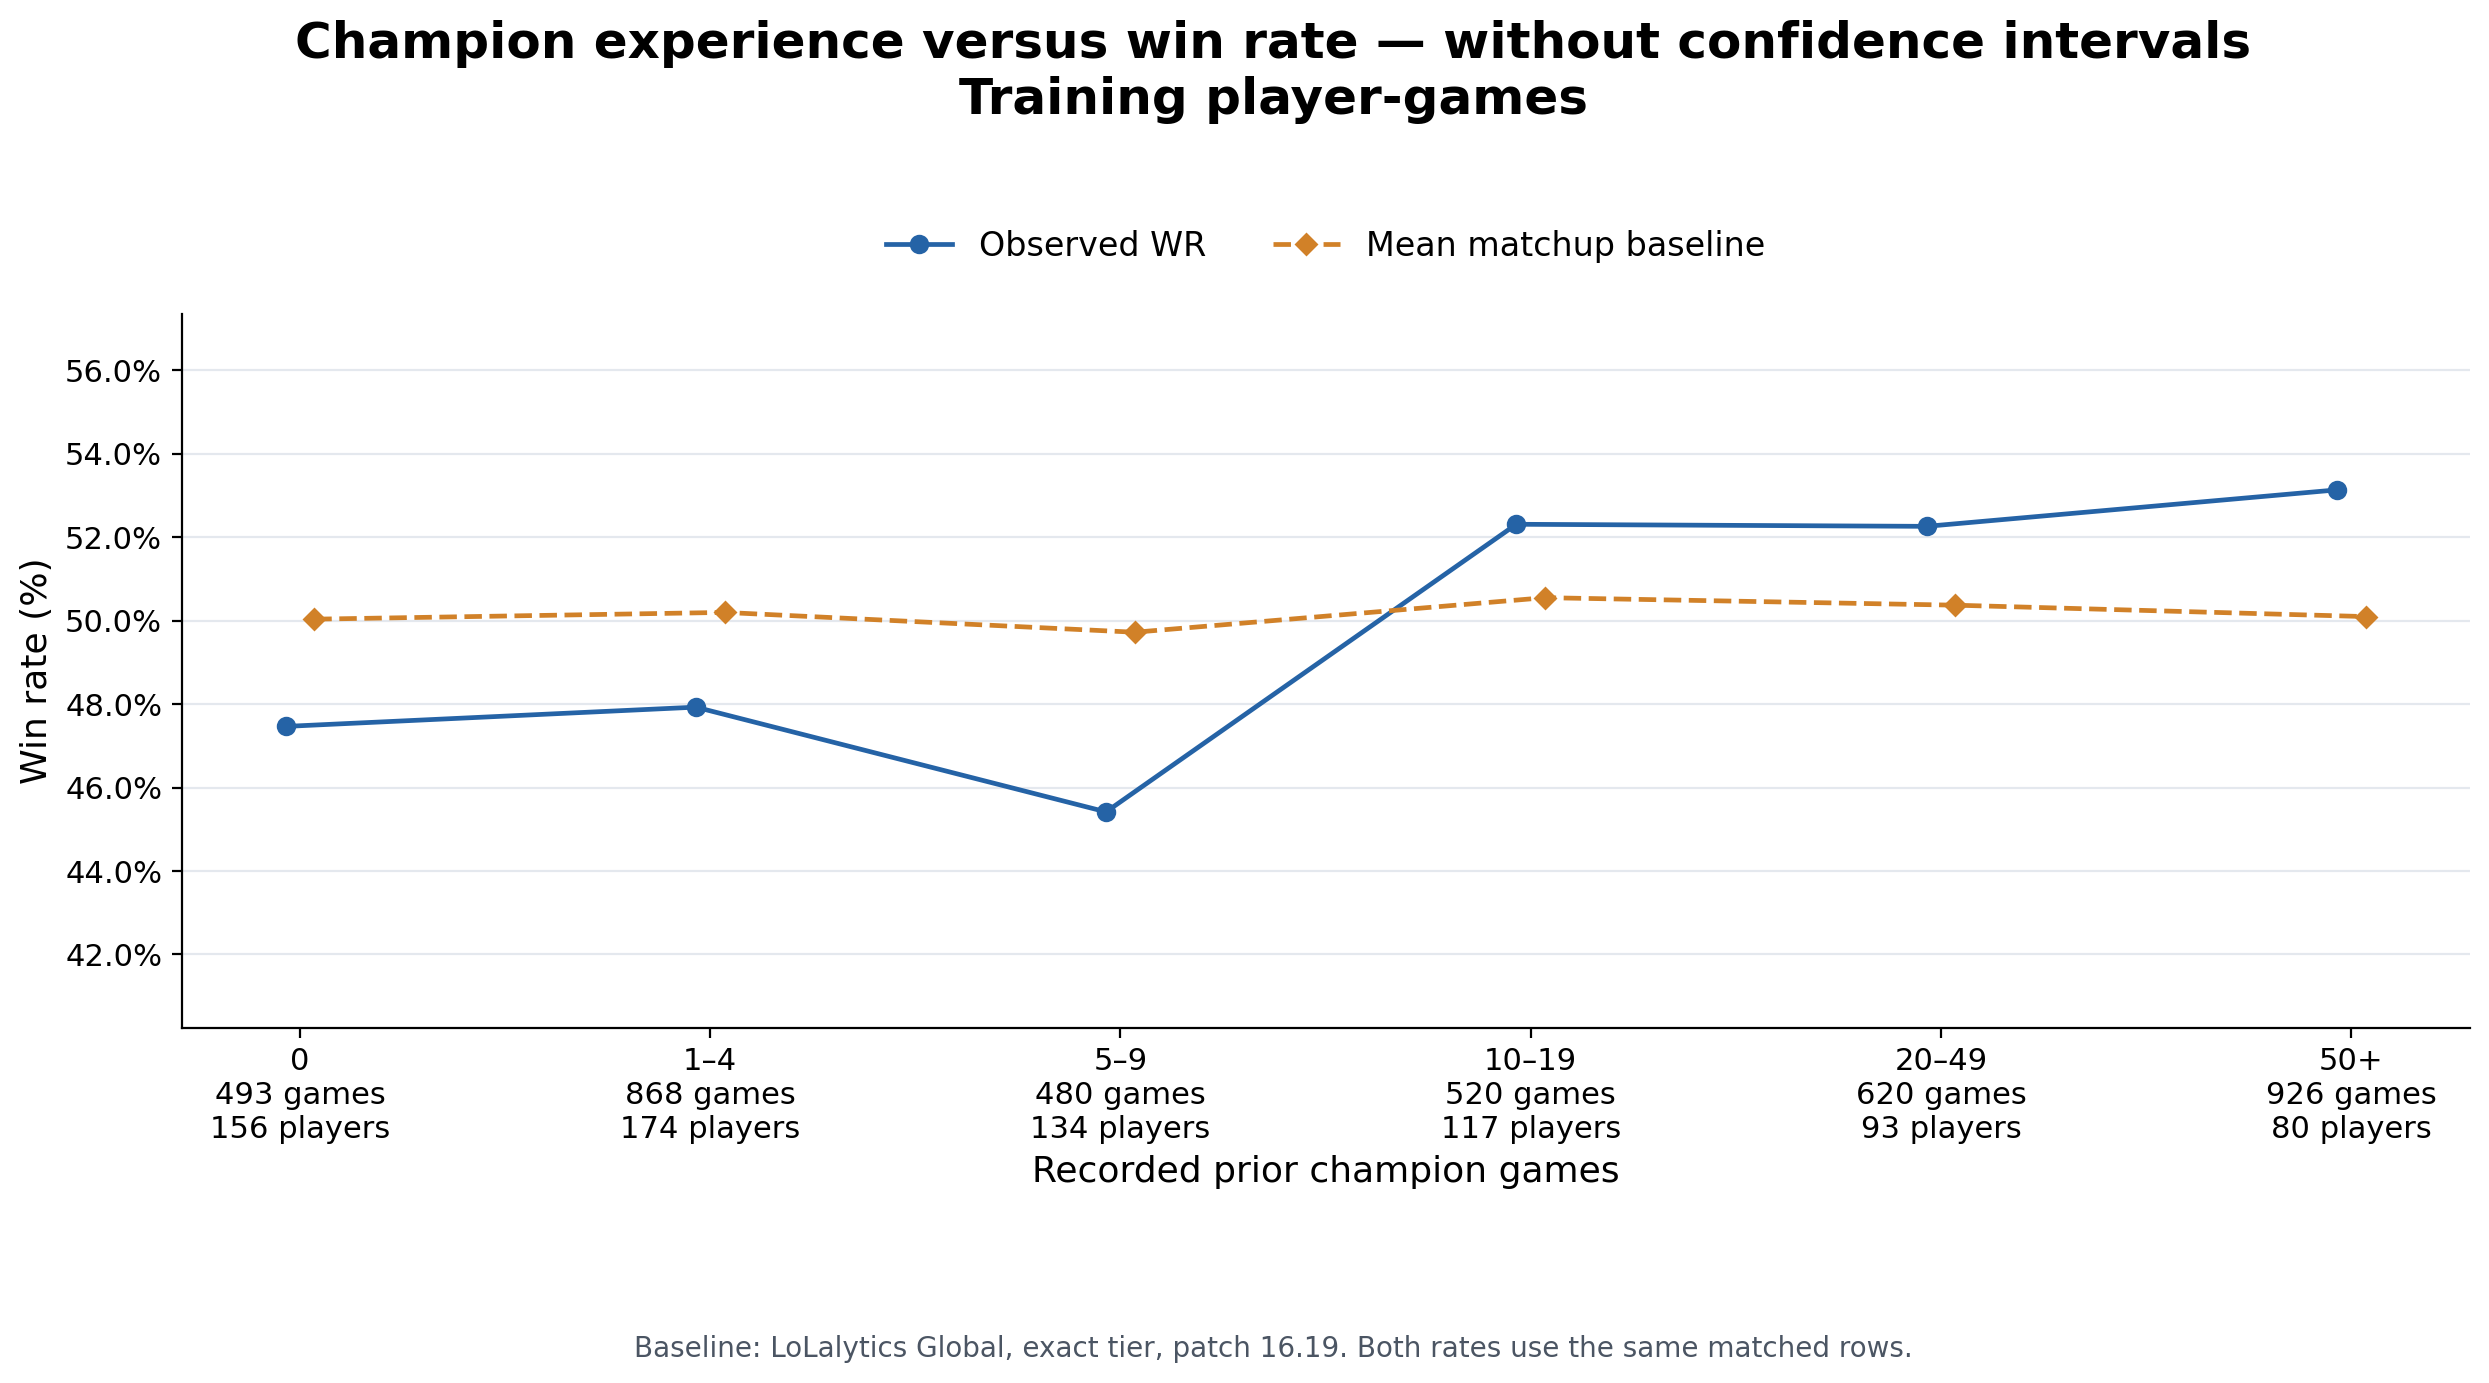

In [5]:
eda_experience_plain_fig, eda_experience_plain_ax = eda_rate_plot(
    eda_experience, 'Champion experience versus win rate — without confidence intervals',
    'Recorded prior champion games', show_ci=False)
eda_experience_plain_ax.set_ylabel('Win rate (%)')
eda_experience_plain_ax.set_xlim(eda_experience_ci_limits[0])
eda_experience_plain_ax.set_ylim(eda_experience_ci_limits[1])
plt.show()


### 8. Performance above or below baseline by OTP rate

Each point is `100 × mean(actual win − raw matchup probability)` on the same matched rows as Figure 1. The zero line indicates equality with the matched benchmark, not a universal 50% win rate.


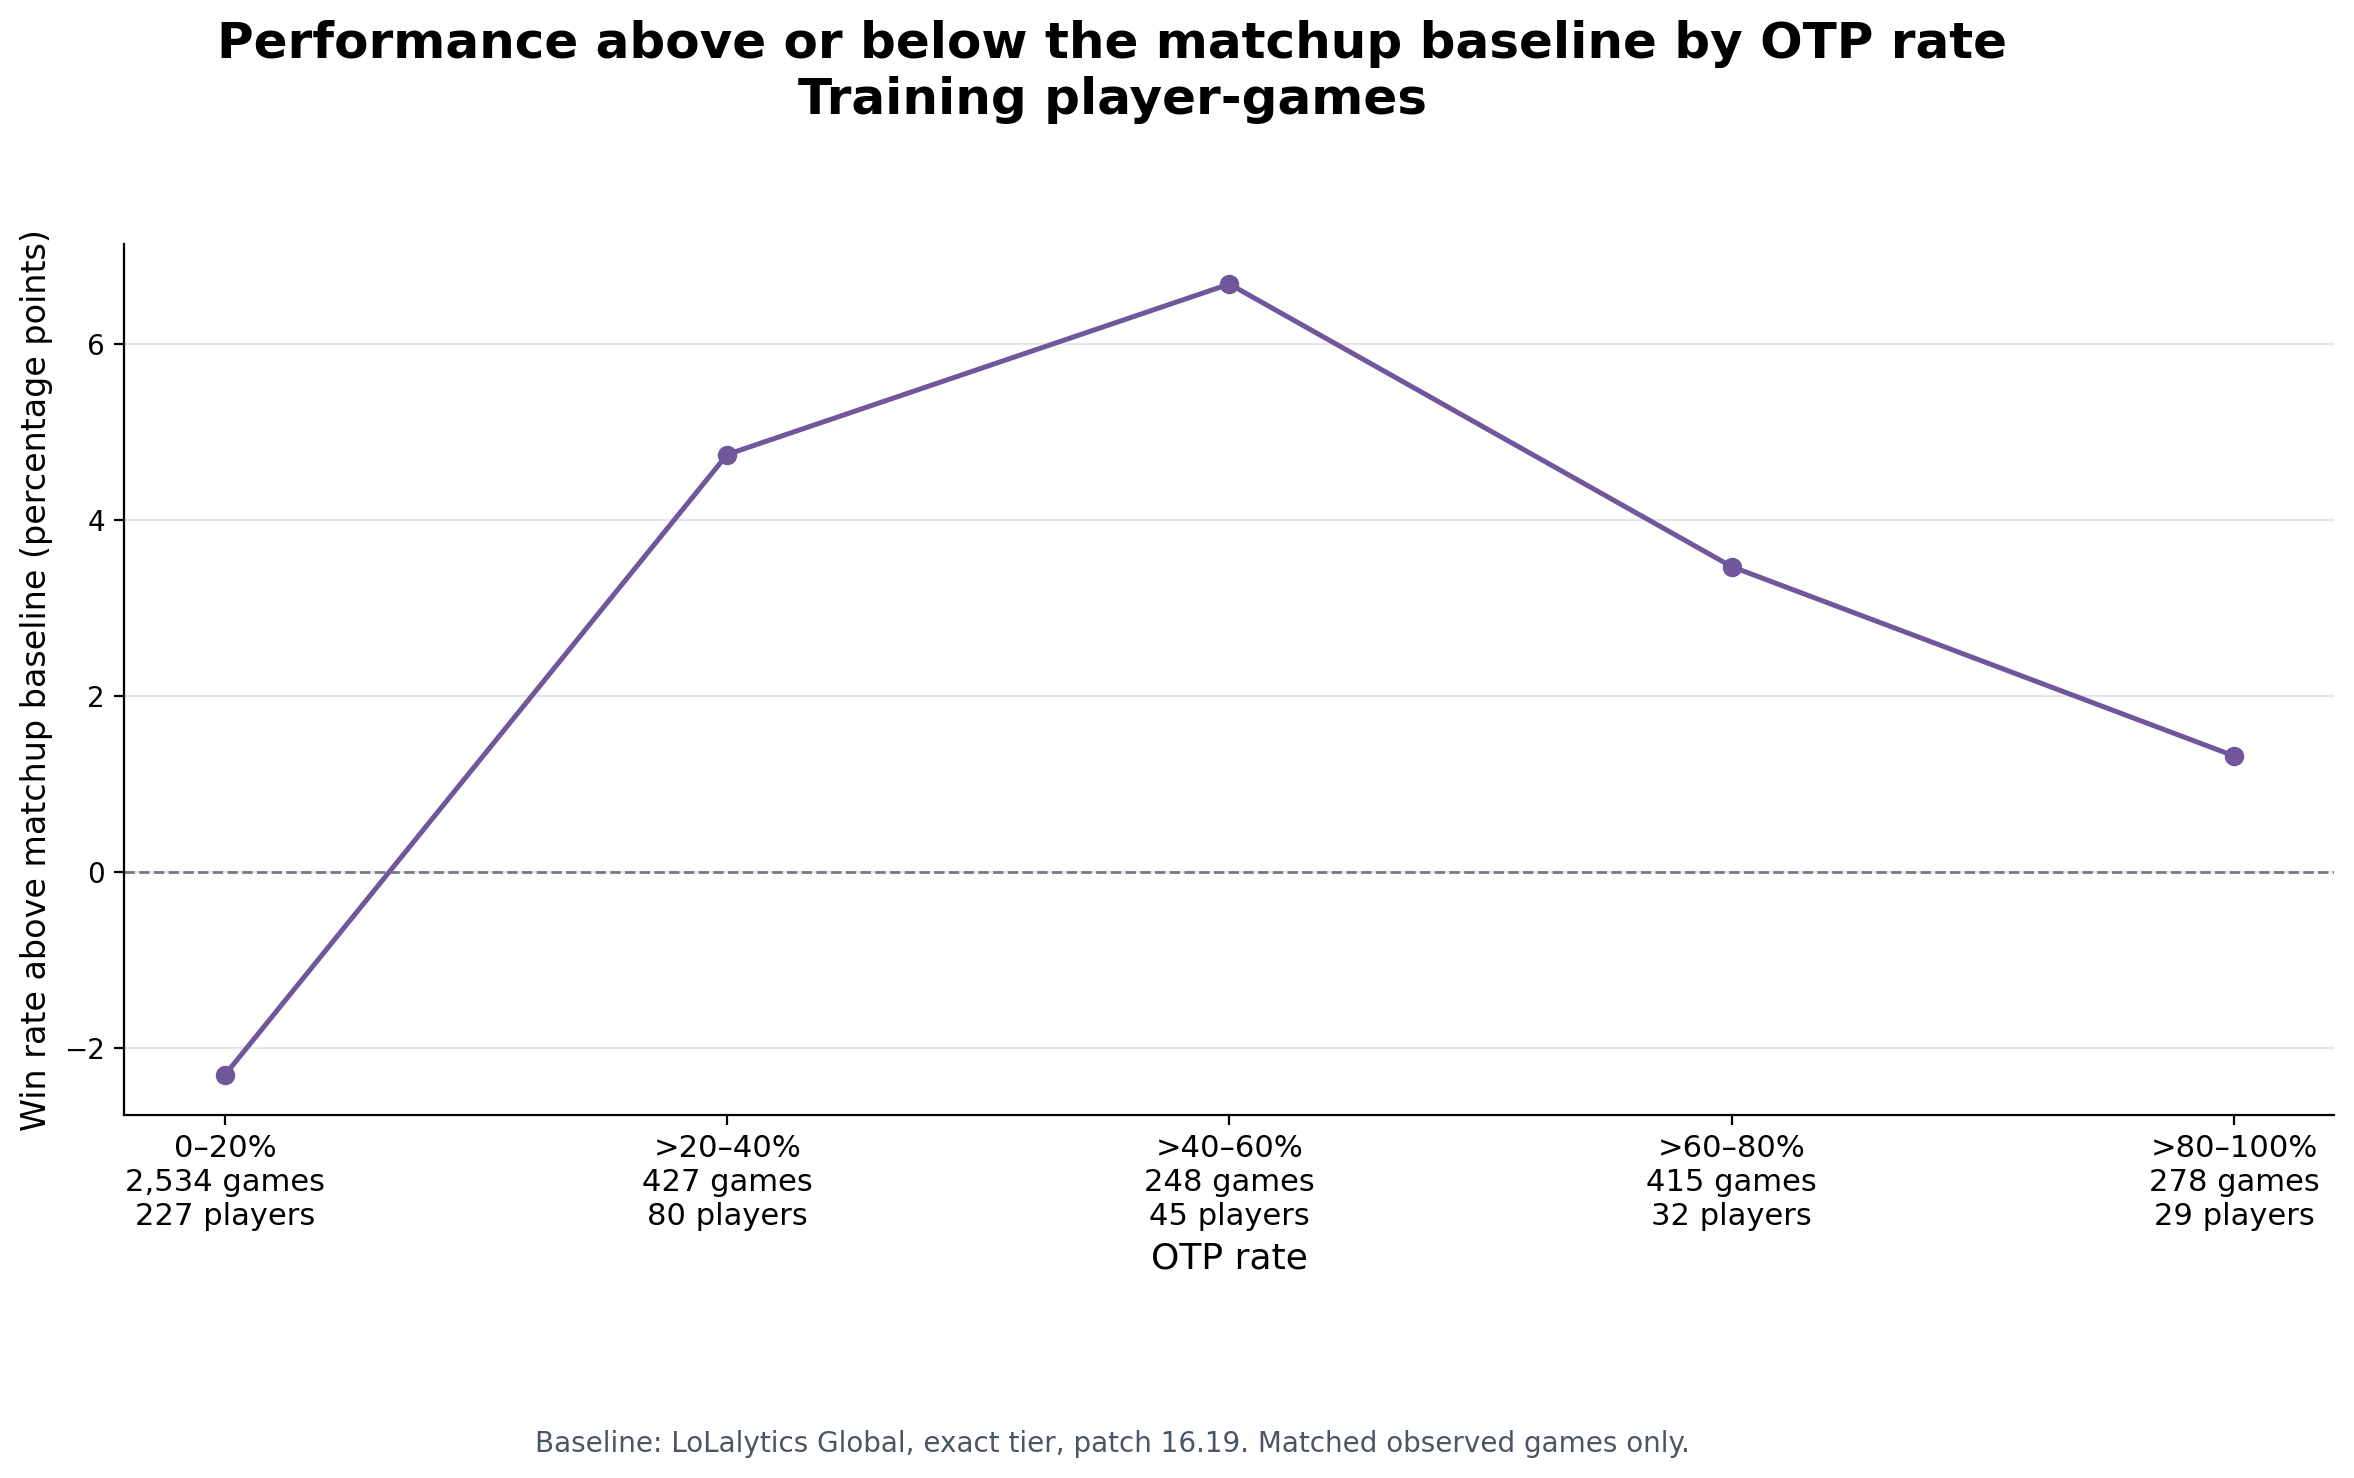

In [6]:
eda_otp_rows = eda_matched.loc[eda_matched.usage_share.notna()].copy()
eda_otp_rows['excess_pp'] = 100 * (eda_otp_rows.win - eda_otp_rows.matchup_probability)
eda_otp_gap = eda_otp_rows.groupby('usage_bin', observed=True).agg(
    excess_pp=('excess_pp', 'mean'), games=('win', 'size'), players=('puuid', 'nunique')).reindex(USAGE_LABELS)
eda_otp_gap[['games', 'players']] = eda_otp_gap[['games', 'players']].fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(13, 7.5), facecolor='white')
fig.suptitle('Performance above or below the matchup baseline by OTP rate\nTraining player-games',
             fontsize=18, fontweight='bold', y=.98)
x = np.arange(len(USAGE_LABELS))
ax.plot(x, eda_otp_gap.excess_pp, 'o-', color='#70569A', linewidth=1.8, markersize=6)
ax.axhline(0, color='#737B85', linestyle='--', linewidth=1)
ax.set_xticks(x, [f'{label}\n{r.games:,} games\n{r.players} players'
    for label, r in zip(USAGE_LABELS, eda_otp_gap.itertuples())], fontsize=11)
ax.set_xlabel('OTP rate', fontsize=13)
ax.set_ylabel('Win rate above matchup baseline (percentage points)', fontsize=12)
ax.grid(axis='y', color='#E4E8EE', linewidth=.8)
ax.spines[['top', 'right']].set_visible(False)
fig.text(.5, .025, 'Baseline: LoLalytics Global, exact tier, patch 16.19. Matched observed games only.',
         ha='center', fontsize=10, color='#4B5563')
fig.subplots_adjust(left=.12, right=.97, top=.83, bottom=.25)
plt.show()


### 9. Does the OTP pattern differ by rank?

Cell values are observed-minus-benchmark percentage points and distinct-player counts. The diverging scale is centered at zero with symmetric limits. Cells with fewer than five players are masked and labeled **Limited data**; genuinely empty cells are labeled **No games**. These are descriptive differences, not rank-specific fitted effects.


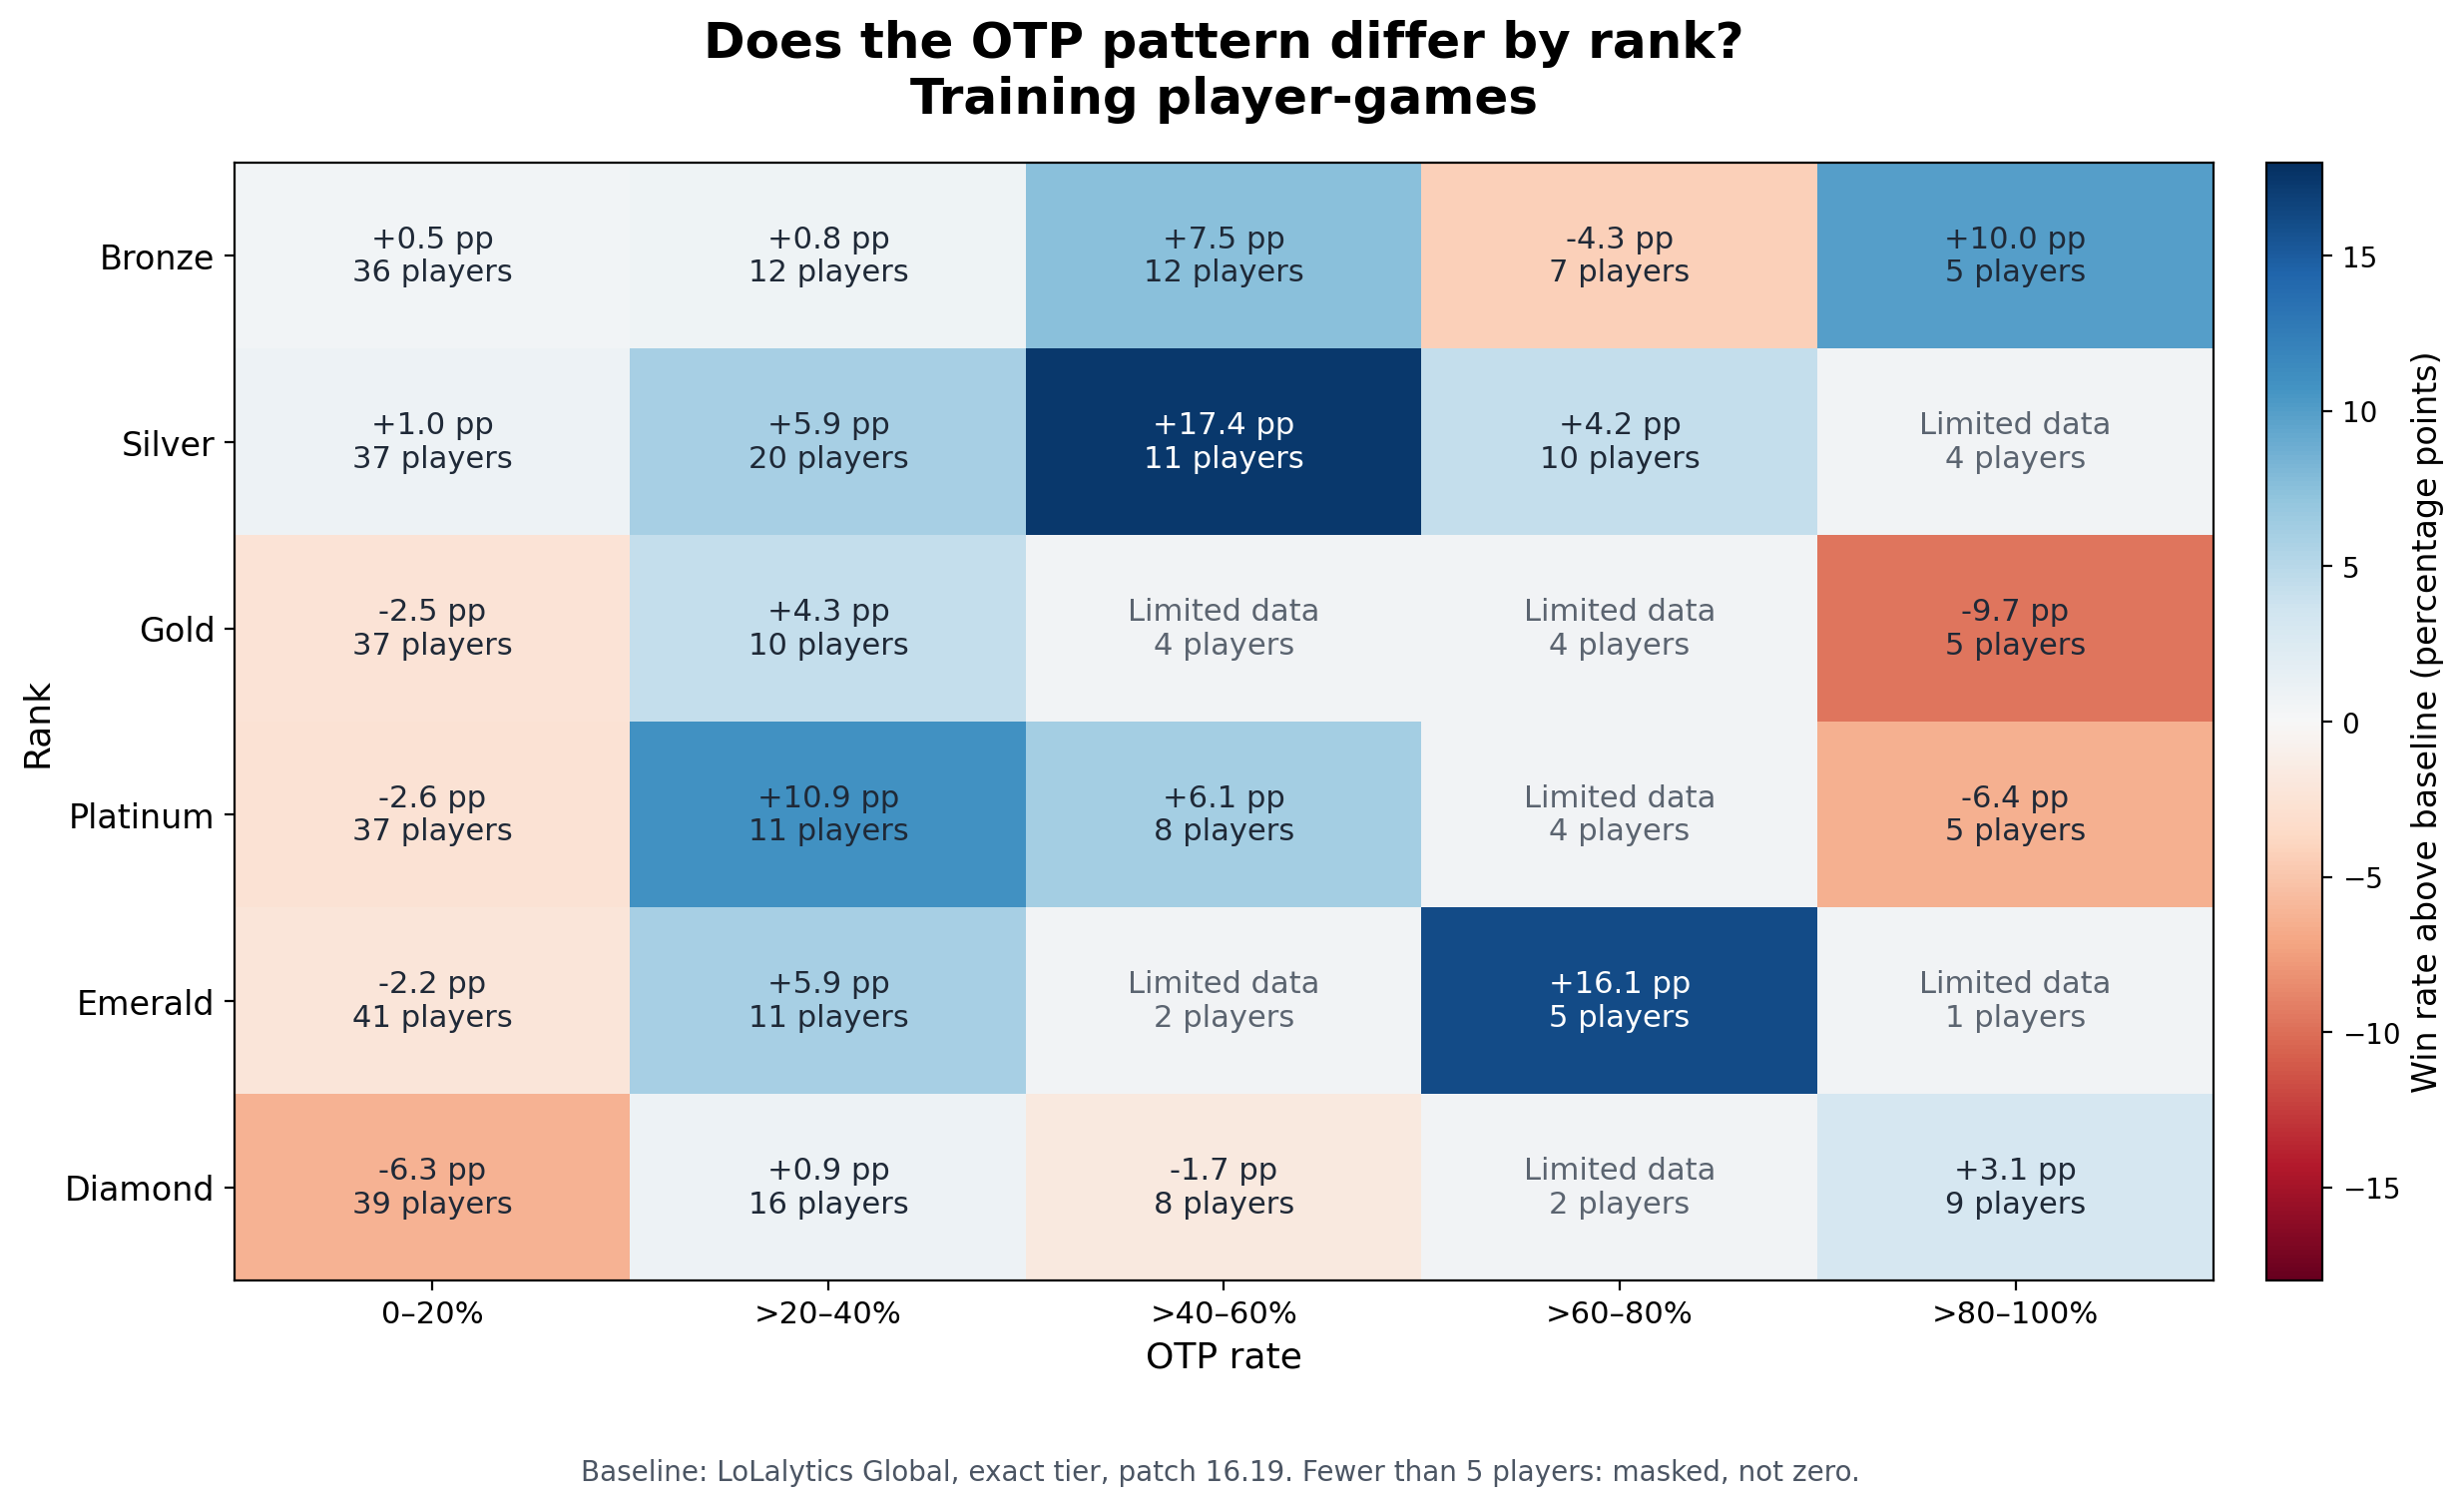

In [7]:
from matplotlib.colors import TwoSlopeNorm

eda_rank_otp = eda_otp_rows.groupby(['model_rank', 'usage_bin'], observed=True).agg(
    excess_pp=('excess_pp', 'mean'), games=('win', 'size'), players=('puuid', 'nunique'))
eda_rank_otp = eda_rank_otp.reindex(pd.MultiIndex.from_product(
    [RANK_LABELS, USAGE_LABELS], names=['model_rank', 'usage_bin']))
eda_rank_gap_grid = eda_rank_otp.excess_pp.unstack('usage_bin').reindex(index=RANK_LABELS, columns=USAGE_LABELS)
eda_rank_players = eda_rank_otp.players.unstack('usage_bin').reindex(index=RANK_LABELS, columns=USAGE_LABELS)
eda_rank_games = eda_rank_otp.games.unstack('usage_bin').reindex(index=RANK_LABELS, columns=USAGE_LABELS)
eda_rank_empty = eda_rank_games.isna() | eda_rank_games.eq(0)
eda_rank_limited = ~eda_rank_empty & eda_rank_players.lt(5)
eda_rank_visible = ~eda_rank_empty & ~eda_rank_limited & eda_rank_gap_grid.notna()
values = eda_rank_gap_grid.to_numpy(dtype=float)
visible = eda_rank_visible.to_numpy()
limit = max(1., float(np.ceil(np.max(np.abs(values[visible]))))) if visible.any() else 1.
cmap = plt.get_cmap('RdBu').copy()
cmap.set_bad('#F1F3F5')
fig, ax = plt.subplots(figsize=(13, 8), facecolor='white')
image = ax.imshow(np.ma.masked_where(~visible, values), cmap=cmap, aspect='auto',
                  norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
for i in range(len(RANK_LABELS)):
    for j in range(len(USAGE_LABELS)):
        if eda_rank_empty.iloc[i, j]:
            label, color = 'No games', '#7A828C'
        elif eda_rank_limited.iloc[i, j]:
            label, color = f'Limited data\n{int(eda_rank_players.iloc[i, j])} players', '#5B6470'
        else:
            value = values[i, j]
            label = f'{value:+.1f} pp\n{int(eda_rank_players.iloc[i, j])} players'
            color = 'white' if abs(value) > .65 * limit else '#1F2937'
        ax.text(j, i, label, ha='center', va='center', fontsize=11, color=color)
ax.set_xticks(range(len(USAGE_LABELS)), USAGE_LABELS, fontsize=11)
ax.set_yticks(range(len(RANK_LABELS)), [r.title() for r in RANK_LABELS], fontsize=12)
ax.set_xlabel('OTP rate', fontsize=13)
ax.set_ylabel('Rank', fontsize=13)
ax.set_title('Does the OTP pattern differ by rank?\nTraining player-games',
             fontsize=18, fontweight='bold', pad=18)
colorbar = fig.colorbar(image, ax=ax, pad=.025, fraction=.045)
colorbar.set_label('Win rate above baseline (percentage points)', fontsize=12)
fig.text(.5, .025, 'Baseline: LoLalytics Global, exact tier, patch 16.19. Fewer than 5 players: masked, not zero.',
         ha='center', fontsize=10, color='#4B5563')
fig.subplots_adjust(left=.12, right=.94, top=.85, bottom=.15)
plt.show()


### 10. Recorded main versus another champion

The main is the existing strictly pregame **all-role** most-played champion, with the smallest champion ID breaking count ties. Use the saved `prior_main_champion_id`, not a main identified using the current outcome or future games. Rows without an identifiable pregame main are excluded and counted below.

Players and game contexts differ between these categories. This is not evidence that switching causes a better or worse outcome.


Excluded 5 matched training games without an identifiable pregame main; 3,902 games remain.


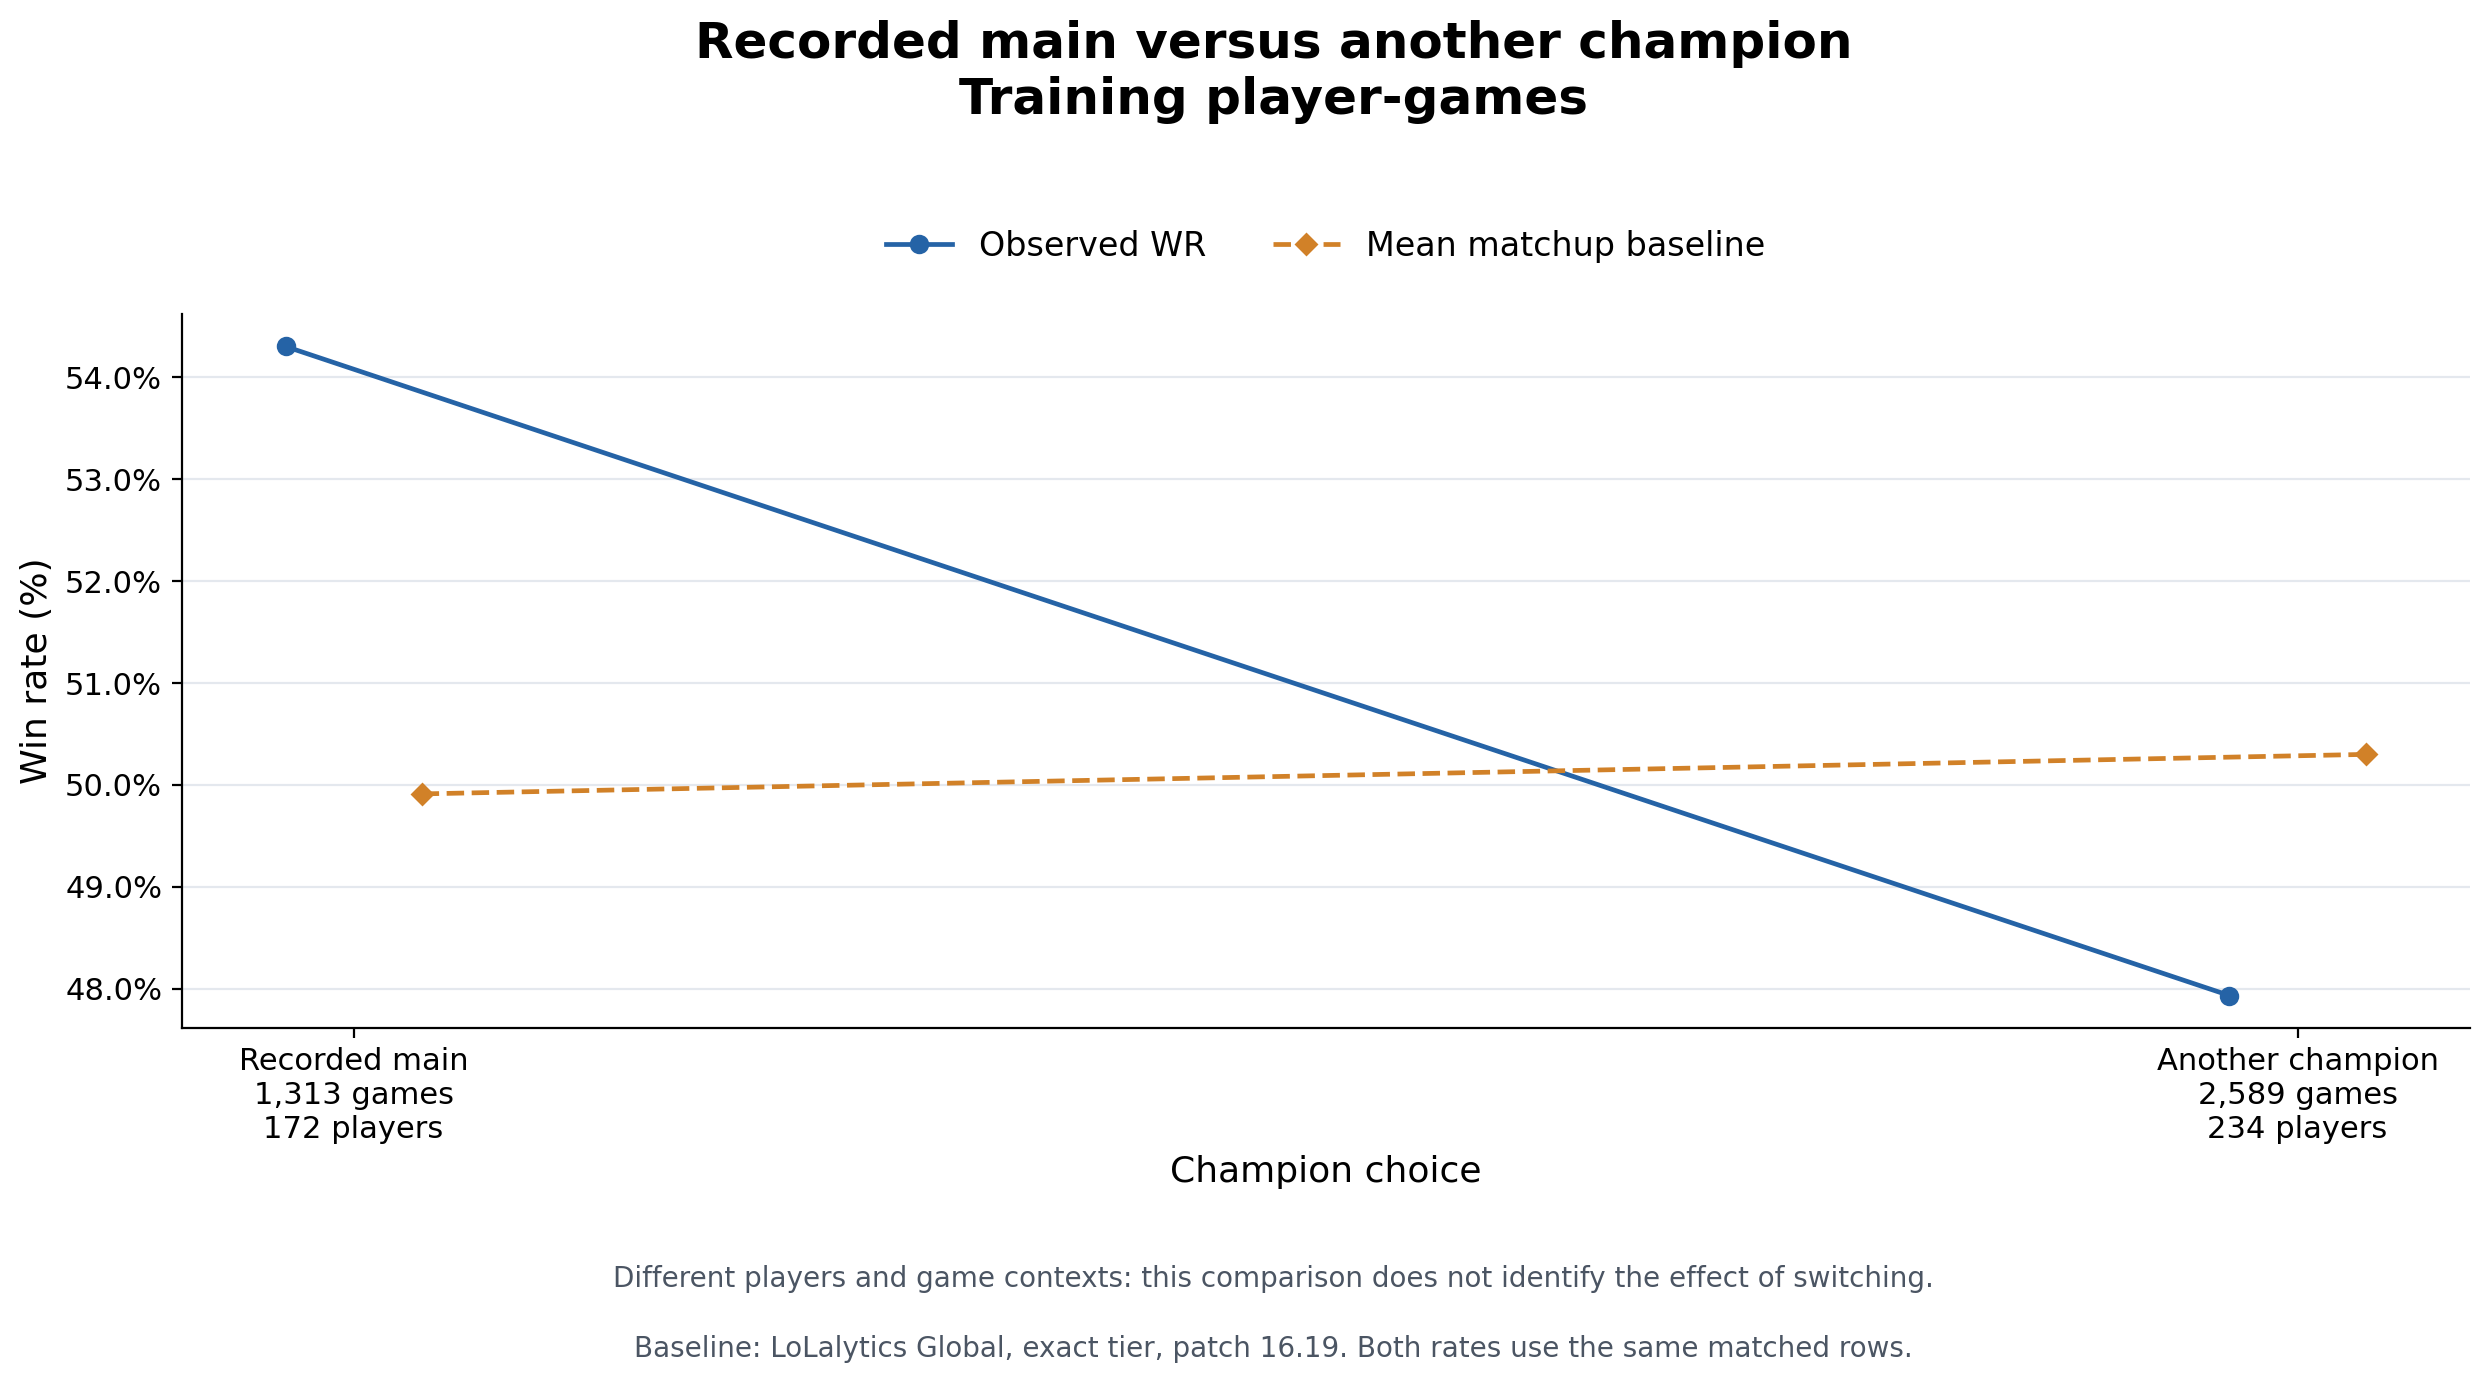

In [8]:
eda_main_excluded = int(eda_matched.prior_main_champion_id.isna().sum())
eda_main_rows = eda_matched.loc[eda_matched.prior_main_champion_id.notna()].copy()
assert eda_main_rows.prior_total_games.gt(0).all()
picked_main = eda_main_rows.champion_id.eq(eda_main_rows.prior_main_champion_id)
assert picked_main.eq(eda_main_rows.is_main_champion).all()
eda_main_rows['champion_choice'] = np.where(picked_main, 'Recorded main', 'Another champion')
eda_main_summary = eda_main_rows.groupby('champion_choice', observed=True).agg(
    wins=('win', 'sum'), games=('win', 'size'), players=('puuid', 'nunique'),
    baseline=('matchup_probability', 'mean')).reindex(['Recorded main', 'Another champion'])
eda_main_summary[['wins', 'games', 'players']] = eda_main_summary[['wins', 'games', 'players']].fillna(0).astype(int)
eda_main_summary['observed_wr'] = eda_main_summary.wins / eda_main_summary.games.where(eda_main_summary.games.gt(0))
print(f'Excluded {eda_main_excluded} matched training games without an identifiable pregame main; '
      f'{len(eda_main_rows):,} games remain.')
eda_main_fig, eda_main_ax = eda_rate_plot(eda_main_summary,
    'Recorded main versus another champion', 'Champion choice', show_ci=False)
eda_main_ax.set_ylabel('Win rate (%)')
eda_main_fig.text(.5, .075, 'Different players and game contexts: this comparison does not identify the effect of switching.',
                  ha='center', fontsize=10, color='#4B5563')
plt.show()


## 7. Matched hierarchical logistic specifications

For observed training row i:

`logit P(win_i) = alpha + X_i beta + rank_i + role_i + champion_baseline_i + player_i + player_champion_i + b_group(i) × n_i/(n_i+k)`

X contains training-standardized **raw matchup probability**, **log1p(prior total games)**, and the selected champion's **all-role historical WR Beta(1,1)**. These retain the existing nonlinear tradeoff model's covariates. No external gain, clipped score, tier-centered percentage, current result, or future history is added.

**Shared:** one experience amplitude b. **Grouped:** the same model plus partially pooled A–J/Unclassified amplitude deviations. Both initially share one k across all groups, with the established log(k) ~ Normal(log 30, 1) prior and training-only estimation. There are no per-champion curve shapes or unnecessary rank/group interactions. J may have any fitted effect; Unclassified has one pooled fallback slope with uncertainty, not independent champion-specific curves.

Regularization: fixed continuous coefficients/intercept Normal(0,2); rank/role contrasts Normal(0,1); shared amplitude Normal(0,1); log player/champion scales Normal(log .3,.7); log player–champion scale Normal(log .15,.5); log group contrast scale Normal(log .3,.7). Latents are noncentered Normal(0,1). Bronze/top are fixed references; champion baselines and group deviations use orthonormal zero-sum contrasts. Player and player–champion effects have proper zero-mean population distributions.

This extends the existing nonlinear C model with rank controls, champion baselines and group slopes. Both primary models use the **same exact Bernoulli NUTS inference**, rather than comparing an optimizer approximation with a sampler. No fitted ordering is forced to match A–J.

Convergence gates: every sampled parameter must have finite rank/folded split R-hat < 1.01 and bulk/tail ESS > 400; zero divergences; each chain acceptance ≥ .8. Tree-depth/BFMI are not emitted by this wrapper. Failed diagnostics save the chains/report and stop evaluation. A smoke run is always labeled smoke-only.

In [7]:
display(pd.Series(modeling.model_specifications(), name='specification').to_frame())
print('Runtime settings:', CONFIG.sampling)
print('Both models fit only observed usable train rows; no validation/test refit.')
model_results = modeling.run_modeling(
    prepared, study_metadata, OUTPUT_PATH, CONFIG, enabled=RUN_MODELING)
if model_results is None:
    print('No model has been fitted in this run.')

,specification
likelihood,"Bernoulli(logit^-1(eta)), played training rows..."
eta,"alpha + standardized [raw matchup probability,..."
shared,one beta_experience for all champions
grouped,shared beta_experience plus partially pooled A...
k,one shared k across groups per model; log(k) ~...
priors,"{'alpha_and_continuous': 'Normal(0,2)', 'rank_..."
identification,Bronze/top reference levels; zero-sum orthonor...
inference,"Pyro 1.9.2 NUTS, exact Bernoulli likelihood; n..."
general_prediction,player and player–champion effects set to zero...
unclassified,one partially pooled group slope with posterio...


Runtime settings: {'chains': 4, 'warmup': 600, 'draws': 1200, 'max_tree_depth': 9, 'train_match_limit': None}
Both models fit only observed usable train rows; no validation/test refit.
RUN_MODELING=False: preparation/EDA only; no optimizer, sampler, collection, or recommendations were run.
No model has been fitted in this run.


## 8. Held-out evaluation, recommendations, and experience curves — populated only after fitting

After both full fits pass diagnostics, outputs include log loss, Brier score, ROC AUC, equal-player losses, calibration bins/plot, and row/player/match counts for identical validation/test rows. Predictions freeze training effects; full-patch rates make this **retrospective benchmark-assisted** evaluation.

Recommendation comparisons use final-test targets. They compare both the played pick and the existing all-role pregame main against eligible same-role choices with strictly higher **raw** matchup benchmarks. A main must itself have prior same-role support and a valid saved benchmark. An actual off-main pick may be a comparison alternative only if it also had prior same-role play. Every choice uses its own count, historical WR and group. Missing reference/alternative benchmarks do not become 50%.

**General** sets learned player and player–champion effects to zero; it does not integrate/marginalize their distributions. **Personalized** conditions on training-supported identity effects. New player/PC/champion identities draw from the appropriate pooled population distribution with uncertainty; identity-stable draws are reused across paired choices. Report paired 95% differences, posterior probability of a higher modeled win probability, uncertain preferences, and pair/equal-target/equal-player summaries. No unplayed outcome is observed or inferred as a label.

Group curves use a common Bronze/top context, training-median continuous features, and zero champion/player/PC baselines. They display posterior uncertainty, training games/players, and observed support; the plotted range stops at each group's training 95th percentile and cannot exceed the common reference total-games count. Rugs show actual observations inside that range; higher observations are not moved to the boundary. Groups need not follow A–J order. Curves vary by group, not independently by every champion. Sparse or single-player support should limit interpretation.

None of these comparisons establishes that switching champions would have caused a win, or that more practice caused the fitted association. Source benchmark error and the external study's transport assumptions are outside the conditional posterior intervals.

In [8]:
if isinstance(model_results, dict) and 'metrics' in model_results:
    display(model_results['metrics'])
    display(model_results['recommendation_summary'])
    for name in ('shared_group_curves','grouped_group_curves','test_calibration'):
        display(Image(filename=str(OUTPUT_PATH / 'figures' / (name + '.png'))))
else:
    print('Evaluation/recommendations/curves are pending a converged full fit; no substantive model result is claimed.')
print('Output version:', OUTPUT_PATH)
for limitation in modeling.LIMITS:
    print('•', limitation)

Evaluation/recommendations/curves are pending a converged full fit; no substantive model result is claimed.
Output version: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/broad_rank_mastery_v1/20261027T202619959682Z_2cff4897
• Recorded prior champion games are season/history-bounded all-role counts, not lifetime experience or mastery points.
• External groups use the workbook's patch 13.7, mostly Gold, EUW/NA/KR study; transport to this cohort is an assumption.
• External gains define groups only and are never added to a predicted probability; J may have a nonzero fitted slope.
• Ranks were checked at collection time, not historically verified for patch 16.19.
• Full-patch matchup rates make this retrospective benchmark-assisted evaluation, not leakage-free prospective prediction.
• Earlier completed held-out games may update saved pregame histories; held-out outcomes never refit parameters.
• General predictions set player and player–champion inte

## Running and resuming

First Run All with `RUN_MODELING=False` and review grouping, Unclassified support, history depths, missingness and splits. The workbook and cohort source stay pinned.

For an optional small execution check: install the optional backend in your notebook environment, set `profile='smoke'`, set `RUN_MODELING=True`, save, and Run All. This produces a separate smoke version; its small chains are not a convergence or performance result.

For the intended full comparison: restore `profile='full'`, enable the same switch, save, and Run All. Interrupting loses at most the current unfinished chain; reopening and Run All with the same sources/settings/code reuses the preparation version and verified completed chains. Full diagnostics must pass before performance or recommendations are exported. No package installation or collection happens automatically.